# FS06 — SA–LSTM vs TPE–LSTM | Direct + Residual | Seeds 41–45

**Input duy nhất của mạng trong file này:** Copper, Aluminium, Tin, WTI. Giữ nguyên thứ tự biến như notebook đầy đủ.

Tách từ bản 6 bộ, chỉ thay ACTIVE_FEATURE_SETS; giữ nguyên kiến trúc, dữ liệu, target, 6 bối cảnh, ngân sách, 5 seeds và lịch search seeds. Không có mô hình đối chứng Naive. Biểu đồ giá ghép giá thật + cả 4 nhánh SA/TPE direct/residual, mặc định minh họa seed 41.

Làm sạch dữ liệu vẫn kiểm tra hợp cột của cả 6 bộ như bản gốc để tránh mỗi file bị lọc ngày khác nhau. Các cột ngoài FS06 không được đưa vào input mạng. FS03/FS05 không có Copper trong input mạng; nhánh residual vẫn cần giá phiên trước khi hoàn nguyên.

Mặc định FULL_MODE như bản gốc; QUICK_MODE chỉ kiểm tra luồng. Notebook mới chưa có kết quả huấn luyện. Không tự chọn biến bằng Spearman. Tách file không làm giảm tổng số fits nếu chạy đủ cả 6 file.


## 1. Giao thức của một file

- 1 bộ × 6 bối cảnh × 2 phương pháp × 2 target × 5 seeds = **120 final fits**, gồm **60 cặp SA/TPE**.
- FULL_MODE: 16 trials/phương pháp/target/seed = **320 search fits + 120 final fits = 440 fits**.
- QUICK_MODE: 4 trials/phương pháp/target/seed = **80 search fits + 120 final fits = 200 fits**.
- Giữ đủ seeds 41,42,43,44,45 cho cả tuning và final; mean/std tính trong từng bộ/ratio/scheme/target/phương pháp.
- 80%,92.5%,95%: expanding. 90%: expanding, rolling_756, recency_weighted. Validation là 10% phần trước test, scaler chỉ fit train.
- Tuning riêng theo bộ/target/seed trên 80/20 expanding; không xem test hoặc refit train+validation. Đây là holdout theo từng split, không tái huấn luyện định kỳ trong test.
- Test giữa các ratio chồng lấn; các seeds dùng chung ngày test. Không xem chúng là các tập test độc lập.


In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('optuna') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','optuna>=4.2,<6'])


In [2]:
from pathlib import Path
import gc,json,time,math,hashlib,zipfile,platform
from datetime import datetime,timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from IPython.display import display,FileLink
import tensorflow as tf
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('TensorFlow:',tf.__version__,'Optuna:',optuna.__version__,'GPU:',tf.config.list_physical_devices('GPU'),flush=True)


TensorFlow: 2.21.0 Optuna: 5.1.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
MODE = 'FULL_MODE'
CSV_PATH = '/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv'
DATA_FILENAME = 'dataset_9_commodities_daily.csv'
FEATURE_SETS = {
    'FS01': ['Copper'],
    'FS02': ['Copper', 'WTI', 'Gold', 'Silver'],
    'FS03': ['WTI', 'Gold', 'Silver'],
    'FS04': ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold'],
    # Legacy14−Cu từ V21; WTI+Cu từ V22/V23.
    'FS05': ['Aluminium', 'Tin', 'Silver', 'Gold'],
    'FS06': ['Copper', 'Aluminium', 'Tin', 'WTI'],
}
ACTIVE_FEATURE_SETS = ['FS06']  # Notebook này chỉ huấn luyện bộ FS06.
assert ACTIVE_FEATURE_SETS and len(ACTIVE_FEATURE_SETS)==len(set(ACTIVE_FEATURE_SETS))
assert set(ACTIVE_FEATURE_SETS) <= set(FEATURE_SETS)
# Làm sạch trên hợp cột của CẢ 6 bộ để giữ cùng ngày dữ liệu giữa các file.
# Input của mạng chỉ lấy từ ACTIVE_FEATURE_SETS trong make_context.
FEATURES = list(dict.fromkeys(['Copper'] + [c for group in FEATURE_SETS.values() for c in group]))
TARGET = 'Copper'
LOOKBACK, HORIZON = 22, 1
RATIOS = (0.80, 0.90, 0.925, 0.95)
PRIMARY_RATIO = 0.90
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')
SEEDS = [41, 42, 43, 44, 45]  # Chạy đủ 5 seeds cho cả search và final.
FORECAST_MODES = ('direct', 'residual')
SEARCH_SEED_BASE = {'direct': 2026, 'residual': 12026}
assert set(FORECAST_MODES) <= set(SEARCH_SEED_BASE)
BASE_METHODS = ('sa_lstm_v22', 'tpe_lstm')
BATCH_SIZE = 64
MODE_CFG = {
    'QUICK_MODE': dict(epochs=5, search_epochs=3, sa_evals=4, earlystop=True),
    'FULL_MODE':  dict(epochs=100, search_epochs=15, sa_evals=16, earlystop=True),
}
assert MODE in MODE_CFG
CFG = MODE_CFG[MODE]
SPACE = {'units_1':(16,96), 'units_2':(24,160), 'learning_rate':(1e-5, 3e-3)}
INITIAL_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SEARCH_PATIENCE, FINAL_PATIENCE = 4, 9
assert min(RATIOS)==.80 and HORIZON==1 and len(set(SEEDS))==len(SEEDS)
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else (Path('/content') if Path('/content').is_dir() else Path.cwd())
OUT = ROOT/'copper_sa_tpe_FS06_direct_residual_seeds41_45'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True,exist_ok=False)
JOBS = [(ratio,scheme) for ratio in RATIOS for scheme in (SCHEMES if ratio==PRIMARY_RATIO else ('expanding',))]
METHOD_LABELS = [f'{method}_{mode}' for mode in FORECAST_MODES for method in BASE_METHODS]
print('Output:',OUT)
print(f'{MODE}: {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*CFG["sa_evals"]*len(SEEDS)} search fits'
      f' + {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*len(JOBS)*len(SEEDS)} final fits',flush=True)

display(pd.DataFrame([dict(feature_set=fs,n_features=len(FEATURE_SETS[fs]),features=', '.join(FEATURE_SETS[fs])) for fs in ACTIVE_FEATURE_SETS]))


Output: /kaggle/working/copper_sa_tpe_FS06_direct_residual_seeds41_45/20261126T135617971746Z
FULL_MODE: 320 search fits + 120 final fits


,feature_set,n_features,features
0,FS06,4,"Copper, Aluminium, Tin, WTI"


## 2. Dữ liệu dùng chung

Làm sạch trên hợp các cột của các bộ đang bật để mọi bộ có cùng ngày train/validation/test. Không nội suy bằng tương lai. Chấp nhận WTI âm nếu CSV có giá dầu âm; Copper và giá kim loại phải dương.


In [4]:
def resolve_csv(csv_path, filename, input_root=Path('/kaggle/input')):
    """Ưu tiên đường dẫn chỉ định, sau đó tìm Kaggle/Colab/local; Colab cho upload."""
    if csv_path is not None:
        p=Path(csv_path).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f'CSV_PATH không tồn tại: {p}. Đặt CSV_PATH=None nếu muốn tự tìm.')
        return p
    roots=[input_root,Path('/content'),Path.cwd(),Path('/mnt/data')]
    names=(filename,'commodities_9_daily.csv')
    found=[]
    for root in roots:
        if not root.is_dir():continue
        for name in names:
            found.extend(p.resolve() for p in root.rglob(name) if p.is_file())
    found=sorted(set(found))
    if len(found)==1:return found[0]
    if len(found)>1:
        raise FileNotFoundError(f'Tìm thấy nhiều CSV: {found}. Hãy đặt CSV_PATH cụ thể.')
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Không tìm thấy {names}. Upload file hoặc đặt CSV_PATH.')
    uploaded=files.upload()
    if len(uploaded)!=1:
        raise FileNotFoundError('Hãy upload đúng một file CSV và chạy lại cell này.')
    p=Path('/content')/next(iter(uploaded))
    if not p.is_file():p=Path(next(iter(uploaded)))
    if not p.is_file():raise FileNotFoundError(f'Không tìm thấy file mới upload: {p}')
    return p

def clean_data(raw):
    raw=raw.copy()
    raw.columns=[str(c).strip().lstrip('\ufeff') for c in raw.columns]
    aliases={f'Price_{key}':key for key in FEATURES}
    if raw.columns.duplicated().any() or any(a in raw.columns and b in raw.columns for a,b in aliases.items()):
        raise ValueError('Tên biến trùng/nhập nhằng.')
    raw=raw.rename(columns=aliases)
    required=['Date']+FEATURES
    missing=set(required)-set(raw.columns)
    if missing:raise ValueError(f'Thiếu cột: {missing}')
    raw=raw[required].copy()
    raw.Date=pd.to_datetime(raw.Date,errors='coerce',utc=True).dt.tz_convert(None).dt.normalize()
    if raw.Date.isna().any() or raw.Date.duplicated().any():raise ValueError('Ngày không hợp lệ hoặc trùng.')
    for key in FEATURES:raw[key]=pd.to_numeric(raw[key],errors='coerce')
    n=len(raw)
    data=raw.replace([np.inf,-np.inf],np.nan).dropna().sort_values('Date').reset_index(drop=True)
    if len(data)<=1000:raise ValueError('Cần hơn 1000 dòng hợp lệ theo giao thức V22.')
    positive_cols=[key for key in FEATURES if key!='WTI']
    if not (data[positive_cols]>0).all().all():raise ValueError('Giá kim loại <=0: kiểm tra nguồn CSV.')
    return data,dict(rows_source=n,rows_used=len(data),rows_removed=n-len(data),start=str(data.Date.min()),end=str(data.Date.max()))

DATA_PATH=resolve_csv(CSV_PATH,DATA_FILENAME)
data,quality=clean_data(pd.read_csv(DATA_PATH,encoding='utf-8-sig'))
data.to_csv(OUT/'dataset_snapshot.csv',index=False,encoding='utf-8-sig')
DATA_SHA=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
(OUT/'data_quality.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
print(DATA_PATH,quality,flush=True)
display(data.head())


/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv {'rows_source': 2710, 'rows_used': 2710, 'rows_removed': 0, 'start': '2016-01-13 00:00:00', 'end': '2026-11-13 00:00:00'}


,Date,Copper,WTI,Gold,Silver,Aluminium,Tin
0,2016-01-13,1.9560,30.48,1087.1,14.156,1462.5,13305.0
1,2016-01-14,1.9760,31.20,1073.6,13.748,1483.0,13260.0
2,2016-01-15,1.9435,29.42,1090.7,13.896,1473.0,13205.0
3,2016-01-19,1.9775,28.46,1090.7,14.121,1481.0,13225.0
4,2016-01-20,1.9595,26.55,1106.2,14.160,1469.0,13390.0


In [5]:
def make_context(frame, ratio, scheme='expanding', feature_set='FS04', val_fraction=0.10, include_test=False):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = list(FEATURE_SETS[feature_set])
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    visible = frame if include_test else frame.iloc[:split]
    x = xsc.transform(visible[cols]).astype('float32')
    y = ysc.transform(visible[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n) if include_test else None
    assert tr['idx'][-1] < va['idx'][0]
    if include_test: assert va['idx'][-1] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, **({'test':te} if include_test else {}), 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}


In [6]:
audit=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set)
        for part in ['train','val']:
            b=ctx[part]
            audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part=part,samples=len(b['idx']),
                              first_target=str(b['date'][0]),last_target=str(b['date'][-1])))
        test_start=ctx['test_start']
        audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part='test',samples=len(data)-test_start,
                          first_target=str(data.Date.iloc[test_start]),last_target=str(data.Date.iloc[-1])))
        assert 'test' not in ctx
split_df=pd.DataFrame(audit)
split_df.to_csv(OUT/'data_split_summary.csv',index=False)
display(split_df)
search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=ACTIVE_FEATURE_SETS[0])
assert 'test' not in search_ctx


,feature_set,ratio,scheme,part,samples,first_target,last_target
0,FS06,0.800,expanding,train,1929,2016-02-16T00:00:00.000000000,2023-12-06T00:00:00.000000000
1,FS06,0.800,expanding,val,217,2023-12-07T00:00:00.000000000,2024-10-04T00:00:00.000000000
2,FS06,0.800,expanding,test,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,FS06,0.900,expanding,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000
4,FS06,0.900,expanding,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
5,FS06,0.900,expanding,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
6,FS06,0.900,rolling_756,train,734,2021-09-24T00:00:00.000000000,2024-11-12T00:00:00.000000000
7,FS06,0.900,rolling_756,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
8,FS06,0.900,rolling_756,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
9,FS06,0.900,recency_weighted,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000


In [7]:
def training_target(block, forecast_mode):
    if forecast_mode == 'direct':
        return np.asarray(block['y'], dtype='float32')
    if forecast_mode == 'residual':
        return (block['y'] - block['prev']).astype('float32')
    raise ValueError(f'Unknown forecast mode: {forecast_mode}')


def restore_price_scaled(predicted_network_output, previous_copper_scaled, forecast_mode):
    pred=np.asarray(predicted_network_output,dtype='float64').reshape(-1)
    if forecast_mode == 'direct':
        return pred
    if forecast_mode == 'residual':
        prev=np.asarray(previous_copper_scaled,dtype='float64').reshape(-1)
        if pred.shape != prev.shape:raise ValueError('Sai shape giữa prediction và prev Copper')
        return prev+pred
    raise ValueError(f'Unknown forecast mode: {forecast_mode}')


for blockname in ('train','val'):
    b=search_ctx[blockname]
    for mode in FORECAST_MODES:
        target=training_target(b,mode)
        assert np.allclose(restore_price_scaled(target,b['prev'],mode),b['y'],atol=1e-6)
    assert np.allclose(training_target(b,'direct'),b['y'])
    assert np.allclose(training_target(b,'residual')+b['prev'],b['y'],atol=1e-6)
assert search_ctx['train']['idx'].max()<search_ctx['val']['idx'].min()
assert search_ctx['xsc'].n_samples_seen_==search_ctx['val_start']-search_ctx['fit_start']
print('PASS: direct/residual targets, hoàn nguyên giá và scaler train-only.')


PASS: direct/residual targets, hoàn nguyên giá và scaler train-only.


## 3. LSTM direct và residual

Cùng kiến trúc mạng và cửa sổ t−22…t−1 cho cả hai cách học:
- Direct: mạng học Copper(t) đã chuẩn hóa. Output được inverse-transform trực tiếp, **không cộng giá phiên trước**.
- Residual: mạng học Copper(t)−Copper(t−1) trên thang chuẩn hóa. Cộng giá phiên trước rồi inverse-transform.

Tuning SA/TPE riêng cho mỗi target; đối chiếu sampler trong cùng target. Chỉ so sánh giữa target bằng MAE/RMSE/MASE trên giá gốc, không dùng validation MSE của hai target để xếp hạng trực tiếp.


In [8]:
def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (chỉ H=1, HP tìm mới riêng cho từng feature set)."""
    h = hp or INITIAL_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))

    model = tf.keras.Sequential(name='Shared_V22_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')


In [9]:
def train_config(ctx, hp, seed, epochs, patience, forecast_mode, model_path=None):
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(int(seed))
    model = build_sa_lstm(ctx['train']['X'].shape[1:],hp)
    y_train_mode = training_target(ctx['train'],forecast_mode)
    y_val_mode = training_target(ctx['val'],forecast_mode)
    start=time.perf_counter()
    try:
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=patience,restore_best_weights=True),
                   tf.keras.callbacks.TerminateOnNaN()]
        history=model.fit(ctx['train']['X'],y_train_mode,
                          validation_data=(ctx['val']['X'],y_val_mode),
                          epochs=epochs,batch_size=BATCH_SIZE,shuffle=False,
                          sample_weight=sample_weights(len(ctx['train']['idx']),ctx['scheme']),
                          callbacks=callbacks,verbose=2 if MODE=='QUICK_MODE' else 0)
        if not all(np.isfinite(np.asarray(history.history[key])).all() for key in ['loss','val_loss']):
            raise FloatingPointError('Loss không hữu hạn; kiểm tra dữ liệu/hyperparameters')
        pred_val=model.predict(ctx['val']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
        if not np.isfinite(pred_val).all():raise FloatingPointError('Validation prediction không hữu hạn')
        score=float(mean_squared_error(y_val_mode,pred_val))
        fit=dict(val_mse=score,fit_seconds=time.perf_counter()-start,
                 epochs_run=len(history.history['loss']),history=history.history)
        if model_path is not None:model.save(model_path)
        return fit
    finally:
        del model;tf.keras.backend.clear_session();gc.collect()


## 4. Tìm siêu tham số riêng theo bộ biến, target và seed

Mỗi bộ/target/seed có hai lượt search SA/TPE ngân sách bằng nhau trên 80/20 expanding. Hai phương pháp dùng cùng lịch trial seeds trong mỗi cặp. Search seed là `SEARCH_SEED_BASE[target] + seed_index*1000`, với seed_index=0…4 tương ứng seeds 41…45; đây là RNG cho tuning, còn seed huấn luyện cuối chính là 41…45. Không tái sử dụng một cấu hình tìm được của seed khác. Kết quả lưu riêng thư mục theo bộ/seed/target.


In [10]:
def clip_hp(h):
    return {'units_1':int(np.clip(round(h['units_1']), *SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']), *SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'], *SPACE['learning_rate']))}

def neighbor(h, rng, temp):
    # SA neighborhood defined in architecture space and log-LR space.
    h = dict(h); dim = rng.choice(['units_1','units_2','learning_rate'])
    if dim == 'learning_rate':
        h[dim] = float(h[dim] * np.exp(rng.normal(0, 0.65)))
    else:
        h[dim] = int(h[dim] + rng.choice([-1,1])*rng.choice([8,16,24]))
    return clip_hp(h)


In [11]:
def search_method(method, forecast_mode, ctx, folder, budget, search_seed):
    assert method in BASE_METHODS and forecast_mode in FORECAST_MODES
    model_key=f'{method}_{forecast_mode}'
    rows=[];start=time.perf_counter()
    def evaluate(hp,k):
        fit=train_config(ctx,hp,search_seed+k,CFG['search_epochs'],SEARCH_PATIENCE,
                         forecast_mode=forecast_mode)
        score=float(fit['val_mse'])
        if not np.isfinite(score):raise FloatingPointError('Validation MSE không hữu hạn')
        return score,fit
    def record(hp,score,fit,**extra):
        rows.append(dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                         trial=len(rows)+1,val_mse_scaled=score,
                         best_val_mse_scaled=min([r['best_val_mse_scaled'] for r in rows]+[score]),
                         fit_seconds=fit['fit_seconds'],epochs_run=fit['epochs_run'],
                         trial_train_seed=search_seed+len(rows),elapsed_seconds=time.perf_counter()-start,
                         **hp,**extra))
        pd.DataFrame(rows).to_csv(folder/f'{model_key}_search_trials.csv',index=False)
        print(f'{model_key} [{len(rows)}/{budget}] val={score:.7g}, '
              f'best={rows[-1]["best_val_mse_scaled"]:.7g}',flush=True)
    if method=='sa_lstm_v22':
        rng=np.random.default_rng(search_seed)
        current=clip_hp(INITIAL_HP);current_loss=float('inf')
        for k in range(budget):
            temperature=float(max(.05,.88**k))
            hp=dict(current) if k==0 else neighbor(current,rng,temperature)
            score,fit=evaluate(hp,k)
            effective_temp=max(1e-8,temperature*max(score,current_loss if np.isfinite(current_loss) else score,1e-5))
            accepted=(score<=current_loss) or (rng.random()<np.exp(-max(0.,score-current_loss)/effective_temp))
            if accepted:current,current_loss=dict(hp),score
            record(hp,score,fit,temperature=temperature,accepted=bool(accepted))
    elif method=='tpe_lstm':
        study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(
            seed=search_seed,n_startup_trials=min(10,max(2,budget//3)),multivariate=False),
            pruner=optuna.pruners.NopPruner())
        study.enqueue_trial(dict(INITIAL_HP))
        def objective(trial):
            hp=dict(units_1=trial.suggest_int('units_1',*SPACE['units_1']),
                    units_2=trial.suggest_int('units_2',*SPACE['units_2']),
                    learning_rate=trial.suggest_float('learning_rate',*SPACE['learning_rate'],log=True))
            score,fit=evaluate(hp,trial.number)
            record(hp,score,fit)
            return score
        study.optimize(objective,n_trials=budget,n_jobs=1)
    else:raise ValueError(method)
    assert len(rows)==budget
    best=min(rows,key=lambda r:r['val_mse_scaled'])
    return dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                best_hp={key:best[key] for key in INITIAL_HP},
                best_val_mse_scaled=best['val_mse_scaled'],evaluations=len(rows),
                total_search_epochs=sum(r['epochs_run'] for r in rows),
                search_fit_seconds=sum(r['fit_seconds'] for r in rows),
                search_wall_seconds=time.perf_counter()-start),rows


In [12]:
manifest=dict(mode=MODE, config=CFG, features=FEATURES, feature_sets={fs:FEATURE_SETS[fs] for fs in ACTIVE_FEATURE_SETS}, target=TARGET,
              lookback=LOOKBACK,horizon=HORIZON, ratios=RATIOS,schemes=SCHEMES,
              jobs=JOBS,seeds=SEEDS,forecast_modes=FORECAST_MODES,base_methods=BASE_METHODS,
              space=SPACE, initial_hp=INITIAL_HP,search_seed_base=SEARCH_SEED_BASE,search_reference_ratio=min(RATIOS),
              search_reference_scheme='expanding',dataset=str(DATA_PATH),dataset_sha256=DATA_SHA,
              python=platform.python_version(),versions={p:metadata.version(p) for p in
              ['tensorflow','optuna','numpy','pandas','scikit-learn']})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
search_results=[];search_logs=[]
for feature_set in ACTIVE_FEATURE_SETS:
    search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=feature_set)
    for seed_index,seed in enumerate(SEEDS):
        for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
            folder=OUT/feature_set/f'seed_{seed}'/forecast_mode;folder.mkdir(parents=True,exist_ok=True)
            # SA/TPE của CÙNG mode dùng chung search seed/trial seeds.
            search_seed=SEARCH_SEED_BASE[forecast_mode]+seed_index*1000
            order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
            for method in order:
                print(f'BEGIN search {feature_set} {method}_{forecast_mode}, seed={seed}',flush=True)
                best,logs=search_method(method,forecast_mode,search_ctx,folder,CFG['sa_evals'],search_seed)
                best['seed']=seed;best['folder']=str(folder);search_results.append(best)
                for row in logs:row['seed']=seed
                search_logs.extend(logs)
# Khóa HP cho hai phương pháp ở cả hai target ở mọi seed TRƯỚC khi dự báo test.
(OUT/'locked_best_hyperparameters.json').write_text(json.dumps(search_results,indent=2),encoding='utf-8')
search_df=pd.DataFrame([{k:v for k,v in r.items() if k not in ['best_hp','folder']} for r in search_results])
search_df.to_csv(OUT/'search_comparison.csv',index=False)
search_trials=pd.DataFrame(search_logs);search_trials.to_csv(OUT/'all_search_trials.csv',index=False)
display(search_df)


BEGIN search FS06 sa_lstm_v22_direct, seed=41
sa_lstm_v22_direct [1/16] val=0.003729323, best=0.003729323
sa_lstm_v22_direct [2/16] val=0.003525772, best=0.003525772
sa_lstm_v22_direct [3/16] val=0.003425156, best=0.003425156
sa_lstm_v22_direct [4/16] val=0.005720224, best=0.003425156
sa_lstm_v22_direct [5/16] val=0.003891563, best=0.003425156
sa_lstm_v22_direct [6/16] val=0.003228591, best=0.003228591
sa_lstm_v22_direct [7/16] val=0.005406857, best=0.003228591
sa_lstm_v22_direct [8/16] val=0.006945308, best=0.003228591
sa_lstm_v22_direct [9/16] val=0.006679973, best=0.003228591
sa_lstm_v22_direct [10/16] val=0.003599295, best=0.003228591
sa_lstm_v22_direct [11/16] val=0.004639967, best=0.003228591
sa_lstm_v22_direct [12/16] val=0.003796827, best=0.003228591
sa_lstm_v22_direct [13/16] val=0.003000533, best=0.003000533
sa_lstm_v22_direct [14/16] val=0.005047784, best=0.003000533
sa_lstm_v22_direct [15/16] val=0.00338446, best=0.003000533
sa_lstm_v22_direct [16/16] val=0.003081725, best=

,feature_set,method,forecast_mode,model_key,best_val_mse_scaled,evaluations,total_search_epochs,search_fit_seconds,search_wall_seconds,seed
0,FS06,sa_lstm_v22,direct,sa_lstm_v22_direct,0.003001,16,239,124.642418,147.148221,41
1,FS06,tpe_lstm,direct,tpe_lstm_direct,0.001768,16,200,107.604913,138.514884,41
2,FS06,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000376,16,134,84.385422,125.787354,41
3,FS06,tpe_lstm,residual,tpe_lstm_residual,0.000380,16,159,93.915617,145.572597,41
4,FS06,tpe_lstm,direct,tpe_lstm_direct,0.001855,16,192,105.103591,167.032602,42
5,FS06,sa_lstm_v22,direct,sa_lstm_v22_direct,0.002152,16,222,115.468157,187.373794,42
6,FS06,tpe_lstm,residual,tpe_lstm_residual,0.000380,16,160,92.907682,174.701272,42
7,FS06,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000374,16,143,87.274070,179.121522,42
8,FS06,sa_lstm_v22,direct,sa_lstm_v22_direct,0.002751,16,215,111.909603,213.628819,43
9,FS06,tpe_lstm,direct,tpe_lstm_direct,0.001540,16,227,115.520292,227.420097,43


## 5. Huấn luyện cuối

Khóa toàn bộ HP trước khi đánh giá test. Các model/scalers/loss lưu riêng từng bộ, ratio, scheme, seed.


In [13]:
final_models=[];final_training=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=False)
        assert 'test' not in ctx
        for seed_index,seed in enumerate(SEEDS):
            for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
                order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
                for method in order:
                    model_key=f'{method}_{forecast_mode}'
                    best=next(r for r in search_results if r['feature_set']==feature_set and r['method']==method and
                              r['seed']==seed and r['forecast_mode']==forecast_mode)
                    folder=OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/f'seed_{seed}'
                    folder.mkdir(parents=True,exist_ok=True)
                    model_path=folder/f'{model_key}.keras'
                    print(f'BEGIN final {feature_set} {model_key} ratio={ratio}, scheme={scheme}, seed={seed}',flush=True)
                    fit=train_config(ctx,best['best_hp'],seed,CFG['epochs'],FINAL_PATIENCE,
                                     forecast_mode=forecast_mode,model_path=model_path)
                    pd.DataFrame(fit['history']).to_csv(folder/f'{model_key}_loss.csv',index=False)
                    recipe=dict(feature_set=feature_set,features=ctx['features'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                                ratio=ratio,scheme=scheme,seed=seed,model_path=str(model_path),
                                hp=best['best_hp'],final_val_mse_scaled=fit['val_mse'],
                                final_fit_seconds=fit['fit_seconds'],final_epochs_run=fit['epochs_run'])
                    final_models.append(recipe)
                    final_training.append({k:v for k,v in recipe.items() if k not in ['model_path','hp']})
                    pd.DataFrame(final_training).to_csv(OUT/'final_training.csv',index=False)
        np.savez(OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/'scalers.npz',
                 x_scale=ctx['xsc'].scale_,x_offset=ctx['xsc'].min_,
                 y_scale=ctx['ysc'].scale_,y_offset=ctx['ysc'].min_,features=np.array(ctx['features']))
(OUT/'final_model_recipes.json').write_text(json.dumps(final_models,indent=2),encoding='utf-8')
print('Đã hoàn tất',len(final_models),'final model fits, khóa và lưu toàn bộ model.')


BEGIN final FS06 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=41
BEGIN final FS06 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=41
BEGIN final FS06 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=41
BEGIN final FS06 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=41
BEGIN final FS06 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=42
BEGIN final FS06 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=42
BEGIN final FS06 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS06 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS06 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=43
BEGIN final FS06 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=43
BEGIN final FS06 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=43
BEGIN final FS06 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=43
BEGIN final FS06 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=44
BEGIN final FS06 sa_lstm_v22_direct ratio=0.8, scheme=expand

## 6. Đánh giá trên giá gốc

Direct: inverse-transform output mạng. Residual: cộng Copper(t−1) đã chuẩn hóa vào output mạng rồi inverse-transform. Giá phiên trước vẫn dùng để tính thống kê delta cho cả hai nhánh, nhưng không được cộng vào đầu ra direct.

Báo cáo MAE/RMSE/MSE/MASE/R²/Directional Accuracy và thống kê delta. MASE dùng trung bình |Copper(t)−Copper(t−1)| trên train làm mẫu số. Không có mô hình/đường/bảng Naive. Chỉ đánh giá test sau khi khóa HP và final models. Hai phương pháp và hai target phải có cùng ngày test và giá thật trong từng bối cảnh.


In [14]:
def score_test(ctx,pred_scaled,forecast_mode,network_output):
    y=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['y'],dtype='float64')[:,None]).ravel()
    p=ctx['ysc'].inverse_transform(np.asarray(pred_scaled).reshape(-1,1)).ravel()
    base=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['prev'],dtype='float64')[:,None]).ravel()
    if len(y)!=len(p) or not np.isfinite(p).all():raise FloatingPointError('Test prediction không hợp lệ.')
    mse=float(mean_squared_error(y,p));mae=float(mean_absolute_error(y,p))
    train_values=data[TARGET].iloc[ctx['fit_start']:ctx['val_start']].to_numpy()
    denom=float(np.mean(np.abs(np.diff(train_values))))
    actual_delta=y-base;pred_delta=p-base
    corr=float(np.corrcoef(actual_delta,pred_delta)[0,1]) if (
        np.std(actual_delta)>1e-12 and np.std(pred_delta)>1e-12) else np.nan
    metrics=dict(mae=mae,mse=mse,rmse=float(np.sqrt(mse)),r2=float(r2_score(y,p)),
                 mse_scaled=float(mean_squared_error(ctx['test']['y'],pred_scaled)),
                 mase=mae/denom if denom>0 else np.nan,
                 directional_accuracy_pct=float(100*np.mean(np.sign(pred_delta)==np.sign(actual_delta))),
                 actual_delta_std=float(np.std(actual_delta)),
                 predicted_delta_std=float(np.std(pred_delta)),
                 predicted_delta_mean_abs=float(np.mean(np.abs(pred_delta))),
                 delta_corr=corr)
    return metrics,pd.DataFrame(dict(Date=ctx['test']['date'],actual=y,pred=p,previous_copper=base,
                                     actual_delta=actual_delta,pred_delta=pred_delta,
                                     network_output=np.asarray(network_output).reshape(-1)))

results=[];prediction_parts=[]
for recipe in final_models:
    ratio,scheme,seed,method,forecast_mode=[recipe[k] for k in
                                           ['ratio','scheme','seed','method','forecast_mode']]
    feature_set=recipe['feature_set']
    ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=True)
    model=tf.keras.models.load_model(recipe['model_path'])
    net=model.predict(ctx['test']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
    pred_scaled=restore_price_scaled(net,ctx['test']['prev'],forecast_mode)
    if forecast_mode=='residual':
        assert np.allclose(pred_scaled-ctx['test']['prev'],net,atol=1e-6)
    else:
        assert forecast_mode=='direct' and np.allclose(pred_scaled,net,atol=1e-6)
    m,part=score_test(ctx,pred_scaled,forecast_mode,net)
    row={k:v for k,v in recipe.items() if k not in ['model_path','hp']}
    row.update(m,n_test=len(part),test_start=str(part.Date.min()),test_end=str(part.Date.max()))
    results.append(row)
    for key,value in dict(feature_set=feature_set,ratio=ratio,scheme=scheme,seed=seed,method=method,
                          forecast_mode=forecast_mode,model_key=recipe['model_key']).items():
        part[key]=value
    prediction_parts.append(part)
    pd.DataFrame(results).to_csv(OUT/'metrics_by_run.csv',index=False)
    print(f'TEST {feature_set} {recipe["model_key"]} ratio={ratio} {scheme} seed={seed}: MAE={m["mae"]:.6g}, '
          f'RMSE={m["rmse"]:.6g}, Δcorr={m["delta_corr"]:.4g}',flush=True)
    del model;tf.keras.backend.clear_session();gc.collect()
results_df=pd.DataFrame(results)
predictions_df=pd.concat(prediction_parts,ignore_index=True)
predictions_df.to_csv(OUT/'test_predictions.csv',index=False)

for key,g in predictions_df.groupby(['feature_set','ratio','scheme','seed']):
    assert set(g.model_key)==set(METHOD_LABELS),key
    ref=g[g.model_key==METHOD_LABELS[0]].sort_values('Date')
    for model_key in METHOD_LABELS[1:]:
        other=g[g.model_key==model_key].sort_values('Date')
        assert np.array_equal(ref.Date.to_numpy(),other.Date.to_numpy()),(key,model_key)
        assert np.allclose(ref.actual,other.actual) and np.allclose(ref.previous_copper,other.previous_copper),(key,model_key)
assert len(results_df)==len(ACTIVE_FEATURE_SETS)*len(JOBS)*len(SEEDS)*len(METHOD_LABELS)
print('PASS: cả 4 nhánh SA/TPE direct/residual dùng cùng ngày test và cùng Copper thật/giá phiên trước trong từng job.')
display(results_df)


TEST FS06 sa_lstm_v22_direct ratio=0.8 expanding seed=41: MAE=0.189467, RMSE=0.261235, Δcorr=0.09958
TEST FS06 tpe_lstm_direct ratio=0.8 expanding seed=41: MAE=0.237959, RMSE=0.317684, Δcorr=0.09191
TEST FS06 sa_lstm_v22_residual ratio=0.8 expanding seed=41: MAE=0.0704398, RMSE=0.108958, Δcorr=0.0203
TEST FS06 tpe_lstm_residual ratio=0.8 expanding seed=41: MAE=0.0752777, RMSE=0.112136, Δcorr=0.06353
TEST FS06 tpe_lstm_direct ratio=0.8 expanding seed=42: MAE=0.254342, RMSE=0.348116, Δcorr=0.08836
TEST FS06 sa_lstm_v22_direct ratio=0.8 expanding seed=42: MAE=0.289242, RMSE=0.377162, Δcorr=0.09721
TEST FS06 tpe_lstm_residual ratio=0.8 expanding seed=42: MAE=0.0693803, RMSE=0.108228, Δcorr=-0.003435
TEST FS06 sa_lstm_v22_residual ratio=0.8 expanding seed=42: MAE=0.0688955, RMSE=0.107917, Δcorr=0.02944
TEST FS06 sa_lstm_v22_direct ratio=0.8 expanding seed=43: MAE=0.331459, RMSE=0.389465, Δcorr=0.1306
TEST FS06 tpe_lstm_direct ratio=0.8 expanding seed=43: MAE=0.89974, RMSE=1.07268, Δcorr=0.0

,feature_set,features,method,forecast_mode,model_key,ratio,scheme,seed,final_val_mse_scaled,final_fit_seconds,...,mse_scaled,mase,directional_accuracy_pct,actual_delta_std,predicted_delta_std,predicted_delta_mean_abs,delta_corr,n_test,test_start,test_end
0,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,direct,sa_lstm_v22_direct,0.80,expanding,41,0.002763,37.180134,...,0.007613,5.758850,53.505535,0.107963,0.242913,0.180135,0.099577,542,2024-10-07 00:00:00,2026-11-13 00:00:00
1,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,direct,tpe_lstm_direct,0.80,expanding,41,0.001293,19.271444,...,0.011259,7.232770,50.922509,0.107963,0.294401,0.229436,0.091909,542,2024-10-07 00:00:00,2026-11-13 00:00:00
2,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,residual,sa_lstm_v22_residual,0.80,expanding,41,0.000381,7.206962,...,0.001324,2.141020,50.369004,0.107963,0.009808,0.010340,0.020305,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,residual,tpe_lstm_residual,0.80,expanding,41,0.000382,6.332448,...,0.001403,2.288070,46.125461,0.107963,0.010985,0.027969,0.063534,542,2024-10-07 00:00:00,2026-11-13 00:00:00
4,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,direct,tpe_lstm_direct,0.80,expanding,42,0.001400,14.998564,...,0.013519,7.730743,51.476015,0.107963,0.304283,0.244653,0.088358,542,2024-10-07 00:00:00,2026-11-13 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,residual,sa_lstm_v22_residual,0.95,expanding,44,0.001468,7.030754,...,0.000884,2.046546,54.411765,0.096610,0.002356,0.012604,0.079755,136,2026-05-07 00:00:00,2026-11-13 00:00:00
116,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,direct,sa_lstm_v22_direct,0.95,expanding,45,0.008158,22.689571,...,0.024205,13.572231,45.588235,0.096610,0.166328,0.481653,0.245842,136,2026-05-07 00:00:00,2026-11-13 00:00:00
117,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,direct,tpe_lstm_direct,0.95,expanding,45,0.002155,23.665777,...,0.005286,5.904344,45.588235,0.096610,0.094747,0.205042,0.129777,136,2026-05-07 00:00:00,2026-11-13 00:00:00
118,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,residual,sa_lstm_v22_residual,0.95,expanding,45,0.001475,8.842609,...,0.000888,2.052198,54.411765,0.096610,0.003073,0.011206,-0.071799,136,2026-05-07 00:00:00,2026-11-13 00:00:00


In [15]:
metrics=['mae','rmse','mse','mase','directional_accuracy_pct',
         'delta_corr','actual_delta_std','predicted_delta_std','predicted_delta_mean_abs']
summary=results_df.groupby(['feature_set','ratio','scheme','forecast_mode','method'])[metrics+['final_fit_seconds']].agg(['mean','std'])
summary.to_csv(OUT/'summary_mean_std.csv')
display(summary)

# So SA vs TPE CHỈ trong cùng target mode, ratio, scheme, seed.
paired_sampler=results_df.pivot(index=['feature_set','ratio','scheme','seed','forecast_mode'],columns='method',values=metrics)
difference=pd.DataFrame({f'TPE_minus_SA_{m}':paired_sampler[m]['tpe_lstm']-paired_sampler[m]['sa_lstm_v22']
                         for m in metrics})
for m in ['mae','rmse','mse']:
    denom=paired_sampler[m]['sa_lstm_v22'].replace(0,np.nan)
    difference[f'TPE_{m}_reduction_pct']=100*(paired_sampler[m]['sa_lstm_v22']-paired_sampler[m]['tpe_lstm'])/denom
difference.to_csv(OUT/'paired_comparison_SA_vs_TPE_by_mode.csv');display(difference)

print('TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.')
if len(SEEDS)==1:print('Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.')

# Đối chiếu các bộ biến tại CÙNG ratio/scheme/seed, chỉ mô tả kết quả test.
feature_mae=results_df.pivot(index=['ratio','scheme','seed','forecast_mode'],columns=['feature_set','method'],values='mae')
feature_mae.to_csv(OUT/'feature_set_comparison_mae.csv')
display(feature_mae)

# Chênh lệch target trên giá gốc, giữ nguyên sampler/bộ/split/seed.
target_metrics=['mae','rmse','mse','mase']
if {'direct','residual'} <= set(results_df.forecast_mode):
    paired_target=results_df.pivot(index=['feature_set','ratio','scheme','seed','method'],
                                  columns='forecast_mode',values=target_metrics)
    target_difference=pd.DataFrame({f'residual_minus_direct_{m}':
        paired_target[m]['residual']-paired_target[m]['direct'] for m in target_metrics})
    target_difference.to_csv(OUT/'paired_comparison_residual_vs_direct.csv')
    display(target_difference)


mae  \
                                                                  mean   
feature_set ratio scheme           forecast_mode method                  
FS06        0.800 expanding        direct        sa_lstm_v22  0.272129   
                                                 tpe_lstm     0.427144   
                                   residual      sa_lstm_v22  0.069622   
                                                 tpe_lstm     0.070269   
            0.900 expanding        direct        sa_lstm_v22  0.358981   
                                                 tpe_lstm     0.408122   
                                   residual      sa_lstm_v22  0.078735   
                                                 tpe_lstm     0.078915   
                  recency_weighted direct        sa_lstm_v22  0.529063   
                                                 tpe_lstm     0.805580   
                                   residual      sa_lstm_v22  0.077455   
                                                 tpe_lstm     0.078947   
                  rolling_756      direct        sa_lstm_v22  0.470163   
                                                 tpe_lstm     0.328090   
                                   residual      sa_lstm_v22  0.078227   
                                                 tpe_lstm     0.079578   
            0.925 expanding        direct        sa_lstm_v22  0.348468   
                                                 tpe_lstm     0.397467   
                                   residual      sa_lstm_v22  0.077350   
                                                 tpe_lstm     0.075201   
            0.950 expanding        direct        sa_lstm_v22  0.356125   
                                                 tpe_lstm     0.338086   
                                   residual      sa_lstm_v22  0.072696   
                                                 tpe_lstm     0.072922   

                                                                        \
                                                                   std   
feature_set ratio scheme           forecast_mode method                  
FS06        0.800 expanding        direct        sa_lstm_v22  0.051837   
                                                 tpe_lstm     0.271634   
                                   residual      sa_lstm_v22  0.000578   
                                                 tpe_lstm     0.002808   
            0.900 expanding        direct        sa_lstm_v22  0.044483   
                                                 tpe_lstm     0.077259   
                                   residual      sa_lstm_v22  0.002103   
                                                 tpe_lstm     0.002563   
                  recency_weighted direct        sa_lstm_v22  0.169889   
                                                 tpe_lstm     0.114005   
                                   residual      sa_lstm_v22  0.000508   
                                                 tpe_lstm     0.002303   
                  rolling_756      direct        sa_lstm_v22  0.217211   
                                                 tpe_lstm     0.150267   
                                   residual      sa_lstm_v22  0.001183   
                                                 tpe_lstm     0.000853   
            0.925 expanding        direct        sa_lstm_v22  0.119854   
                                                 tpe_lstm     0.104938   
                                   residual      sa_lstm_v22  0.003163   
                                                 tpe_lstm     0.000092   
            0.950 expanding        direct        sa_lstm_v22  0.137291   
                                                 tpe_lstm     0.073546   
                                   residual      sa_lstm_v22  0.000387   
                                                 tpe_lstm     0.000549   

                                                                  rms

TPE_minus_SA_mae  \
feature_set ratio scheme           seed forecast_mode                     
FS06        0.800 expanding        41   direct                 0.048492   
                                        residual               0.004838   
                                   42   direct                -0.034899   
                                        residual               0.000485   
                                   43   direct                 0.568281   
                                        residual              -0.000405   
                                   44   direct                 0.106419   
                                        residual              -0.001028   
                                   45   direct                 0.086781   
                                        residual              -0.000656   
            0.900 expanding        41   direct                 0.212143   
                                        residual               0.003115   
                                   42   direct                -0.058549   
                                        residual              -0.000184   
                                   43   direct                 0.090335   
                                        residual               0.000004   
                                   44   direct                 0.064663   
                                        residual              -0.004431   
                                   45   direct                -0.062889   
                                        residual               0.002394   
                  recency_weighted 41   direct                 0.369648   
                                        residual               0.005241   
                                   42   direct                 0.129233   
                                        residual               0.002419   
                                   43   direct                 0.330582   
                                        residual              -0.000224   
                                   44   direct                 0.437008   
                                        residual              -0.000778   
                                   45   direct                 0.116112   
                                        residual               0.000798   
                  rolling_756      41   direct                -0.150961   
                                        residual               0.002764   
                                   42   direct                 0.187891   
                                        residual               0.001831   
                                   43   direct                -0.130589   
                                        residual              -0.000356   
                                   44   direct                -0.164442   
                                        residual              -0.000674   
                                   45   direct                -0.452264   
                                        residual               0.003190   
            0.925 expanding        41   direct                 0.094774   
                                        residual               0.000208   
                                   42   direct                -0.156532   
                                        residual               0.000078   
                                   43   direct                 0.314565   
                                        residual              -0.000066   
                                   44   direct                 0.173852   
                                        residual              -0.006687   
                                   45   direct                -0.181667   
                                        residual              -0.004278   
            0.950 expanding        41   direct                 0.000976   
                                        residual               0.001571   
     

TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.


feature_set                                      FS06          
method                                    sa_lstm_v22  tpe_lstm
ratio scheme           seed forecast_mode                      
0.800 expanding        41   direct           0.189467  0.237959
                            residual         0.070440  0.075278
                       42   direct           0.289242  0.254342
                            residual         0.068895  0.069380
                       43   direct           0.331459  0.899740
                            residual         0.069372  0.068967
                       44   direct           0.268800  0.375219
                            residual         0.069879  0.068851
                       45   direct           0.281676  0.368457
                            residual         0.069524  0.068868
0.900 expanding        41   direct           0.294501  0.506644
                            residual         0.076989  0.080104
                       42   direct           0.407385  0.348835
                            residual         0.077548  0.077364
                       43   direct           0.334726  0.425061
                            residual         0.077144  0.077148
                       44   direct           0.381665  0.446328
                            residual         0.081487  0.077056
                       45   direct           0.376630  0.313741
                            residual         0.080506  0.082900
      recency_weighted 41   direct           0.443479  0.813128
                            residual         0.077046  0.082287
                       42   direct           0.808261  0.937494
                            residual         0.078003  0.080422
                       43   direct           0.373972  0.704555
                            residual         0.077483  0.077259
                       44   direct           0.457948  0.894956
                            residual         0.077896  0.077118
                       45   direct           0.561653  0.677766
                            residual         0.076848  0.077646
      rolling_756      41   direct           0.713393  0.562432
                            residual         0.077150  0.079914
                       42   direct           0.175016  0.362907
                            residual         0.078272  0.080103
                       43   direct           0.345977  0.215387
                            residual         0.078562  0.078206
                       44   direct           0.482317  0.317875
                            residual         0.080003  0.079329
                       45   direct           0.634113  0.181849
                            residual         0.077147  0.080337
0.925 expanding        41   direct           0.332341  0.427116
                            residual         0.075114  0.075322
                       42   direct           0.499324  0.342793
                            residual         0.075139  0.075217
                       43   direct           0.186965  0.501530
                            residual         0.075141  0.075075
                       44   direct           0.298610  0.472462
                            residual         0.081923  0.075237
                       45   direct           0.425102  0.243434
                            residual         0.079433  0.075155
0.950 expanding        41   direct           0.382277  0.383253
                            residual         0.072236  0.073807
                       42   direct           0.426769  0.345620
                            residual         0.073295  0.073089
                       43   direct           0.123749  0.371102
                            residual         0.072672  0.072449
                       44   direct           0.366773  0.381181
                            residual         0.072538  0.072681
                       45   direct           0.481058  0.209275
                            resi

residual_minus_direct_mae  \
feature_set ratio scheme           seed method                                   
FS06        0.800 expanding        41   sa_lstm_v22                  -0.119027   
                                        tpe_lstm                     -0.162681   
                                   42   sa_lstm_v22                  -0.220346   
                                        tpe_lstm                     -0.184962   
                                   43   sa_lstm_v22                  -0.262087   
                                        tpe_lstm                     -0.830773   
                                   44   sa_lstm_v22                  -0.198921   
                                        tpe_lstm                     -0.306368   
                                   45   sa_lstm_v22                  -0.212153   
                                        tpe_lstm                     -0.299589   
            0.900 expanding        41   sa_lstm_v22                  -0.217512   
                                        tpe_lstm                     -0.426540   
                                   42   sa_lstm_v22                  -0.329837   
                                        tpe_lstm                     -0.271471   
                                   43   sa_lstm_v22                  -0.257582   
                                        tpe_lstm                     -0.347912   
                                   44   sa_lstm_v22                  -0.300178   
                                        tpe_lstm                     -0.369272   
                                   45   sa_lstm_v22                  -0.296124   
                                        tpe_lstm                     -0.230841   
                  recency_weighted 41   sa_lstm_v22                  -0.366433   
                                        tpe_lstm                     -0.730840   
                                   42   sa_lstm_v22                  -0.730258   
                                        tpe_lstm                     -0.857072   
                                   43   sa_lstm_v22                  -0.296490   
                                        tpe_lstm                     -0.627296   
                                   44   sa_lstm_v22                  -0.380052   
                                        tpe_lstm                     -0.817837   
                                   45   sa_lstm_v22                  -0.484805   
                                        tpe_lstm                     -0.600119   
                  rolling_756      41   sa_lstm_v22                  -0.636243   
                                        tpe_lstm                     -0.482517   
                                   42   sa_lstm_v22                  -0.096743   
                                        tpe_lstm                     -0.282804   
                                   43   sa_lstm_v22                  -0.267414   
                                        tpe_lstm                     -0.137181   
                                   44   sa_lstm_v22                  -0.402314   
                                        tpe_lstm                     -0.238546   
                                   45   sa_lstm_v22                  -0.556966   
                                        tpe_lstm                     -0.101512   
            0.925 expanding        41   sa_lstm_v22                  -0.257228   
                                        tpe_lstm                     -0.351794   
                                   42   sa_lstm_v22                  -0.424186   
                                        tpe_lstm                     -0.267576   
                                   43   sa_lstm_v22                  -0.111824   
                                        tpe_lstm                     -0.426455   
                                   44   sa_lstm_v22                  -0.216686   
                                   

## 7. Biểu đồ ghép direct/residual

Mỗi bộ/ratio/scheme/seed có một biểu đồ giá: giá thật + SA direct + TPE direct + SA residual + TPE residual. Màu phân biệt SA/TPE; nét đứt là direct, nét liền là residual. Các đường đều trên thang giá gốc. Biểu đồ delta cũng ghép đủ bốn nhánh. Hội tụ tuning và loss vẫn giữ riêng theo target.

Mặc định vẽ giá/delta seed 41; sửa PLOT_SEEDS ở cuối cell nếu muốn vẽ các seed khác. CSV vẫn chứa đủ seeds 41–45. Nếu mô hình đã chạy và predictions_df còn trong bộ nhớ, chỉ thay rồi chạy cell biểu đồ; không Run All các cell train. Nếu phiên cũ đã kết thúc, dùng notebook Replot riêng để đọc test_predictions.csv hoặc ZIP kết quả.


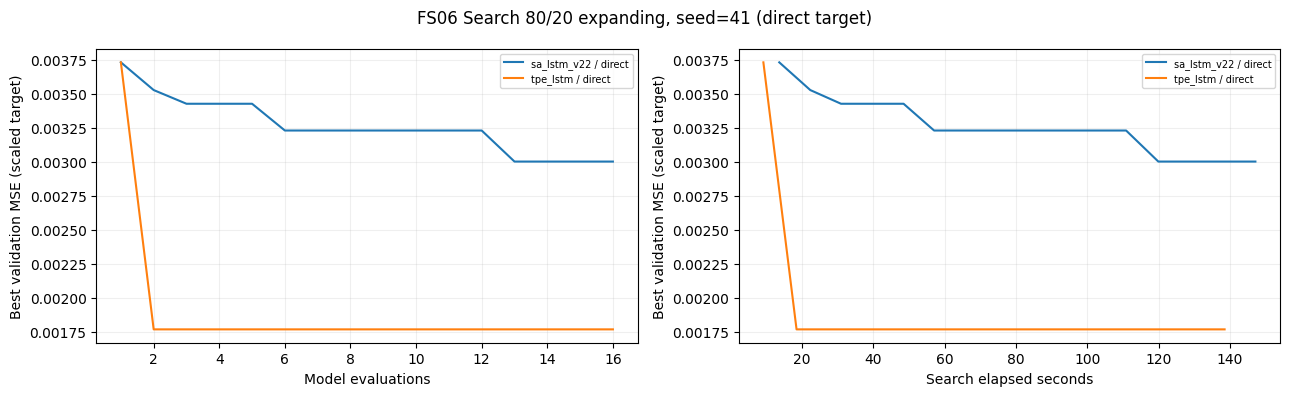

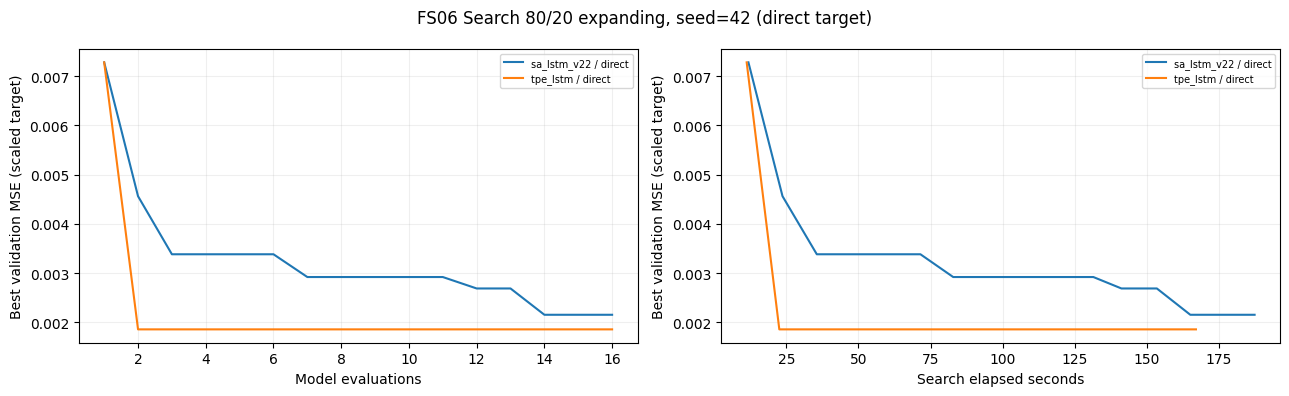

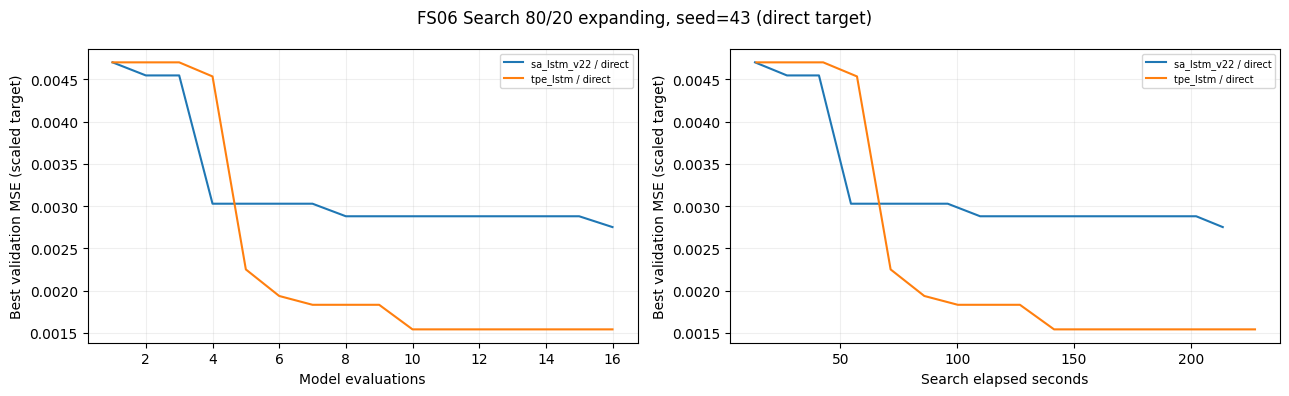

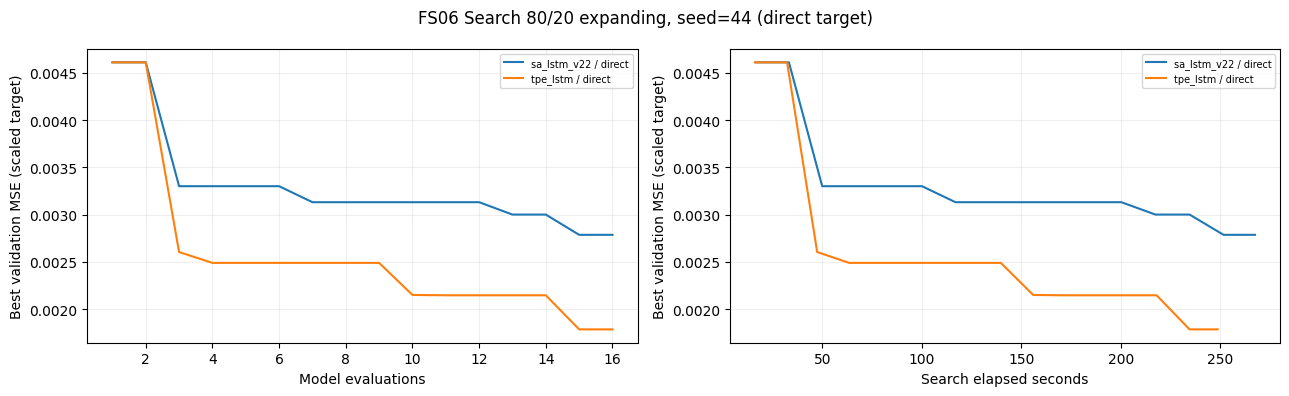

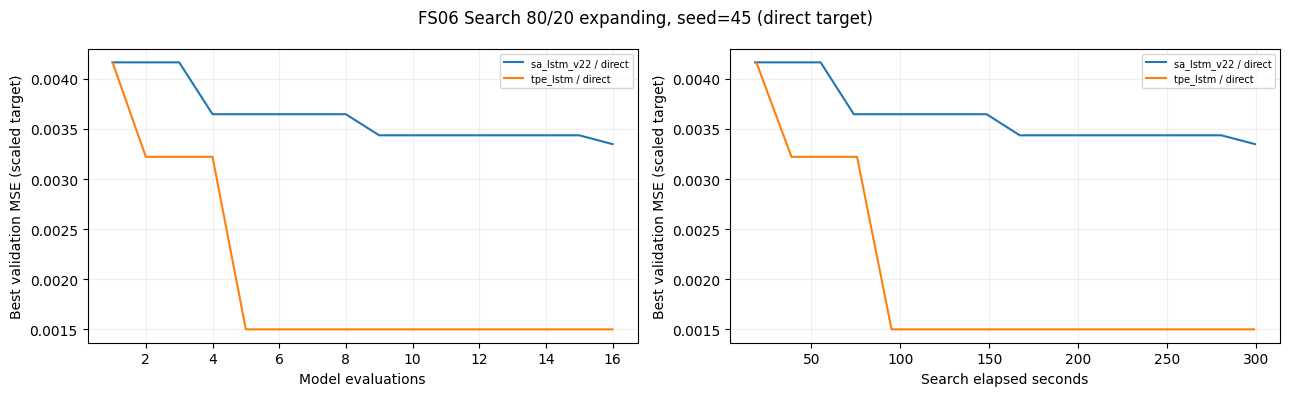

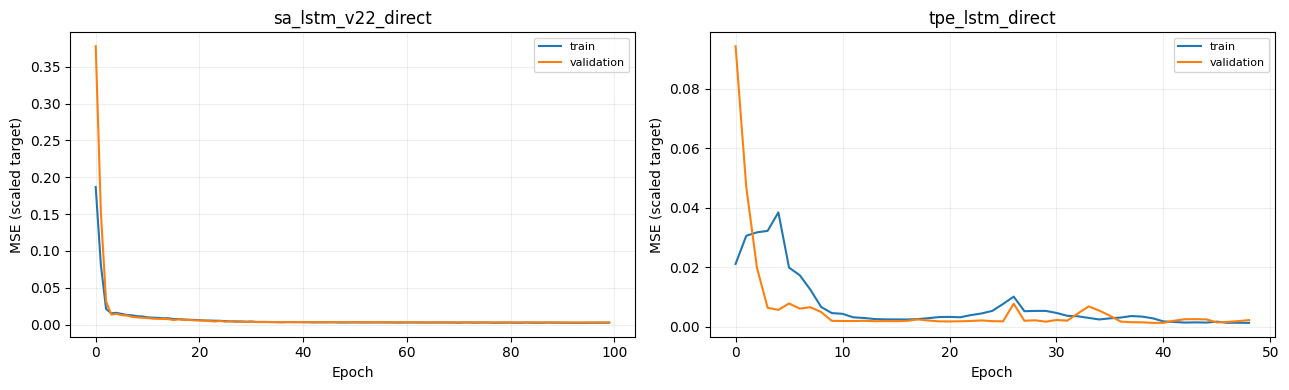

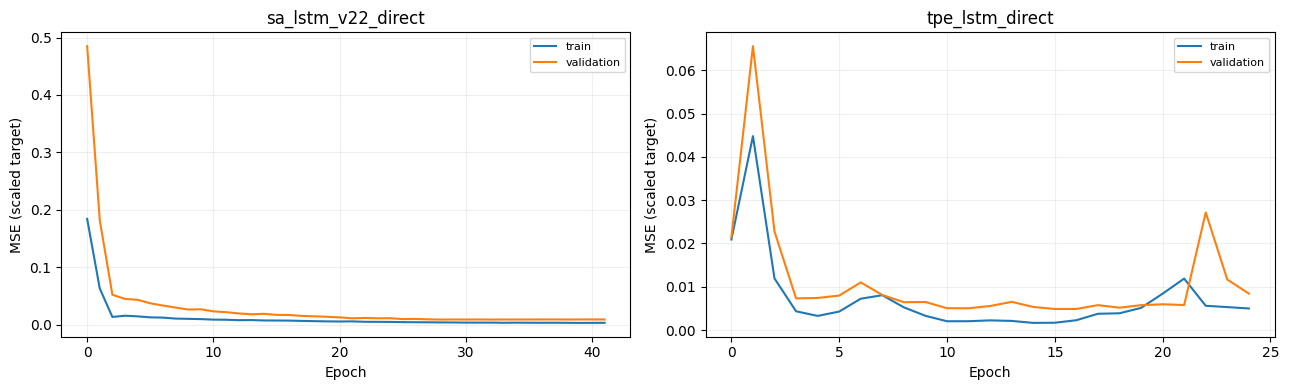

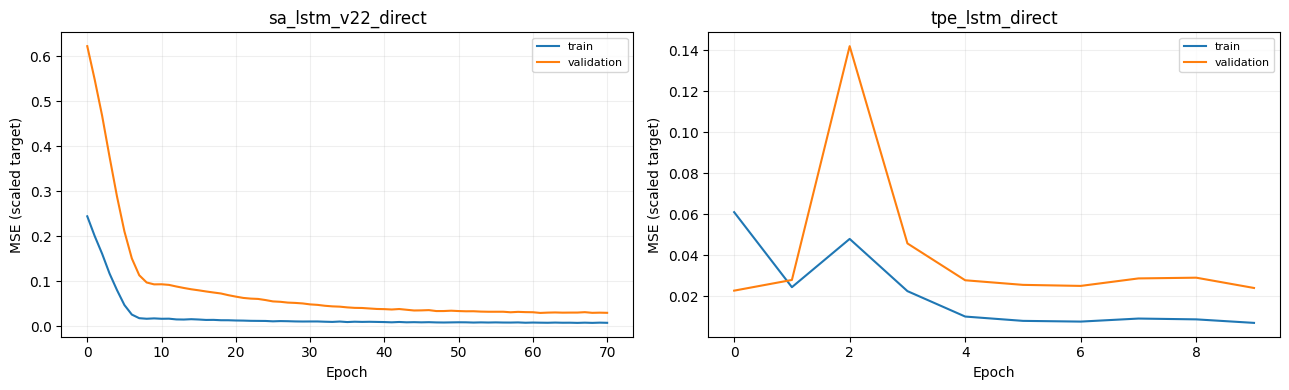

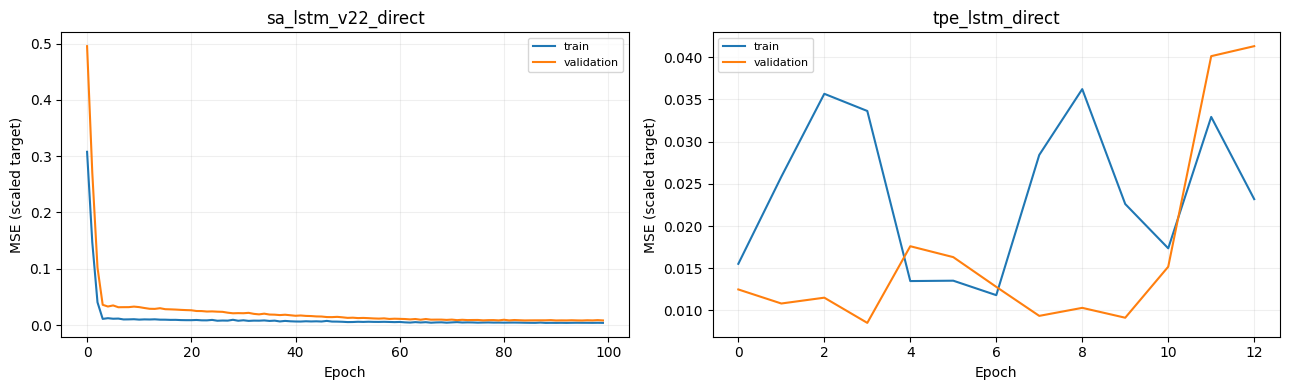

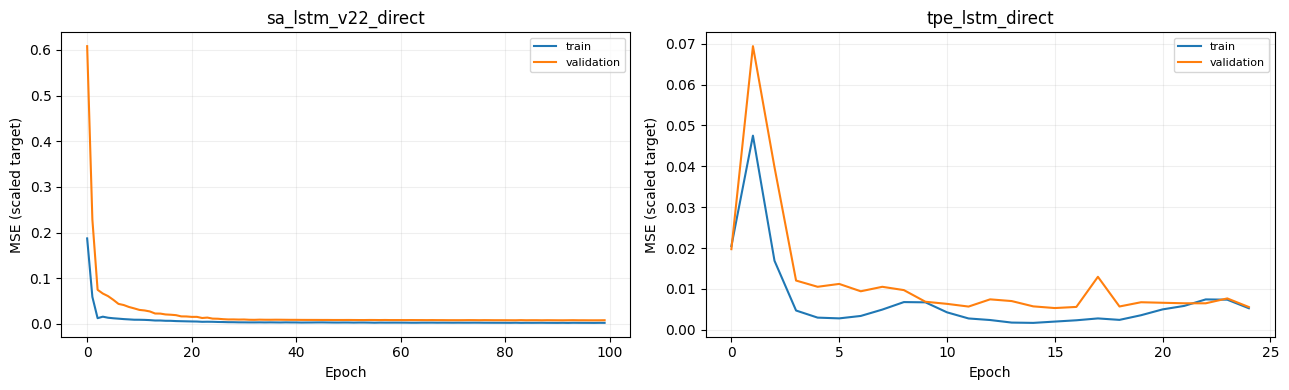

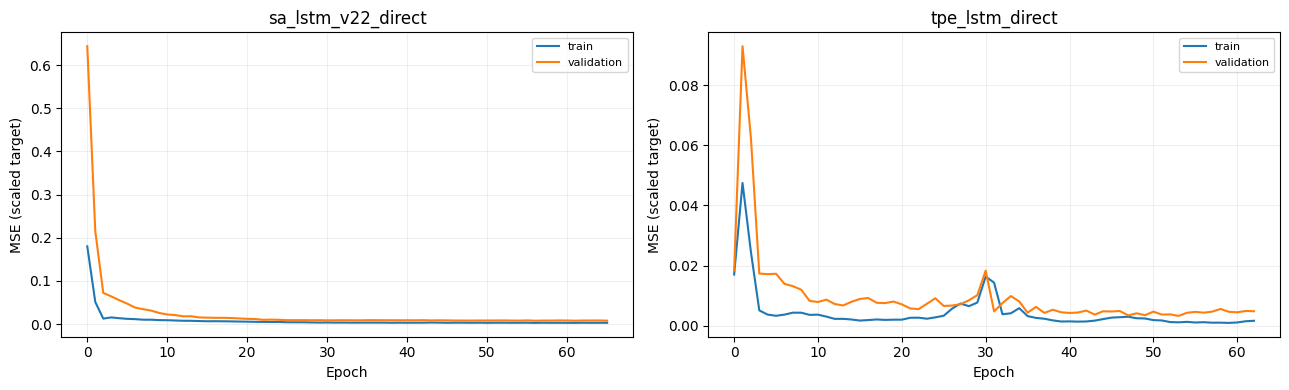

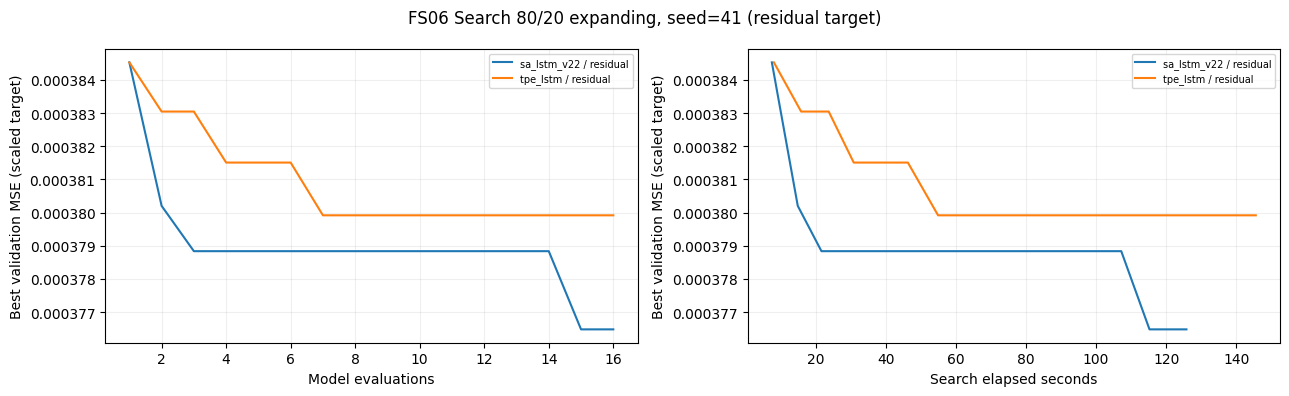

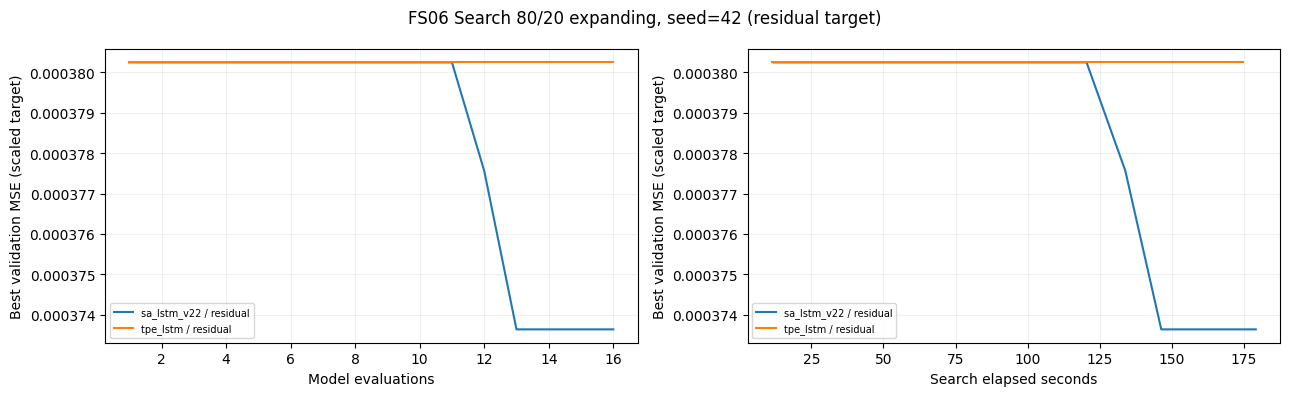

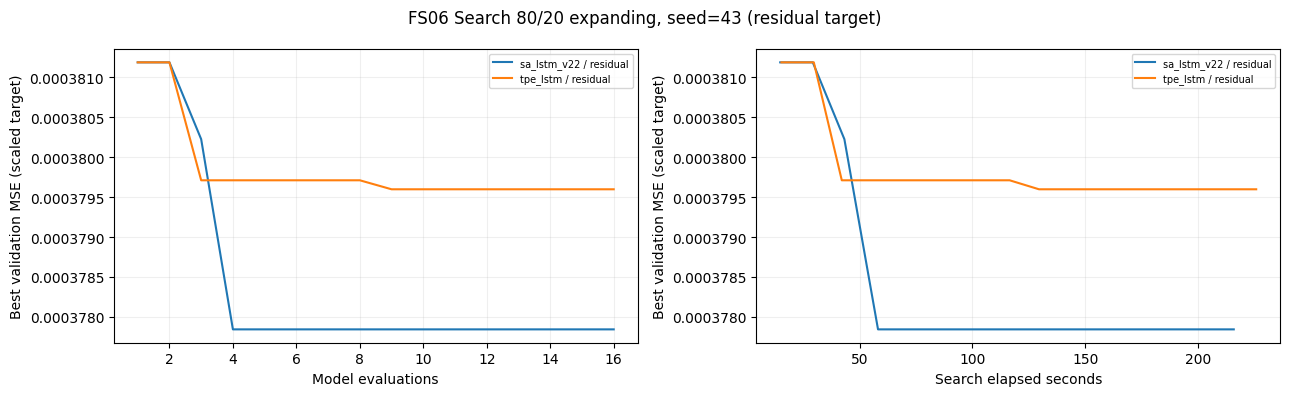

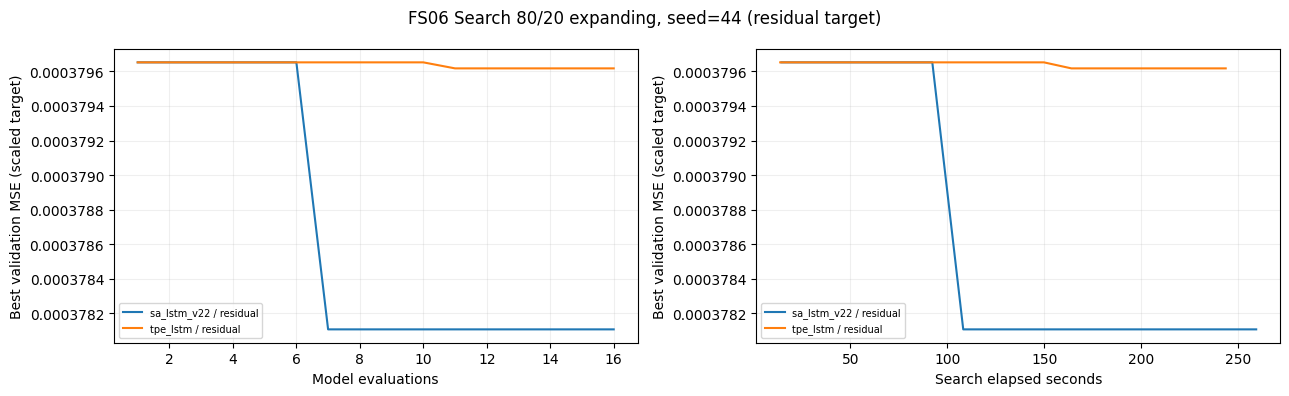

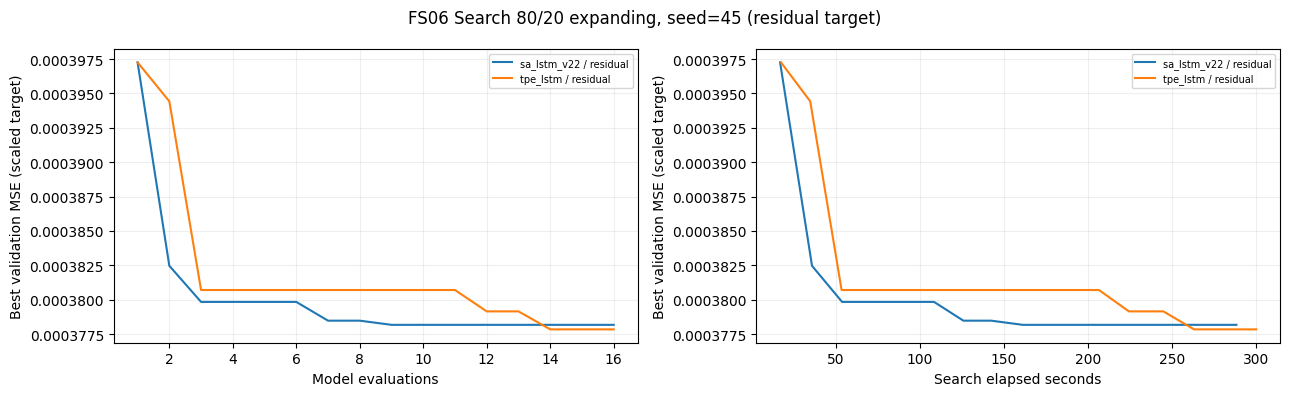

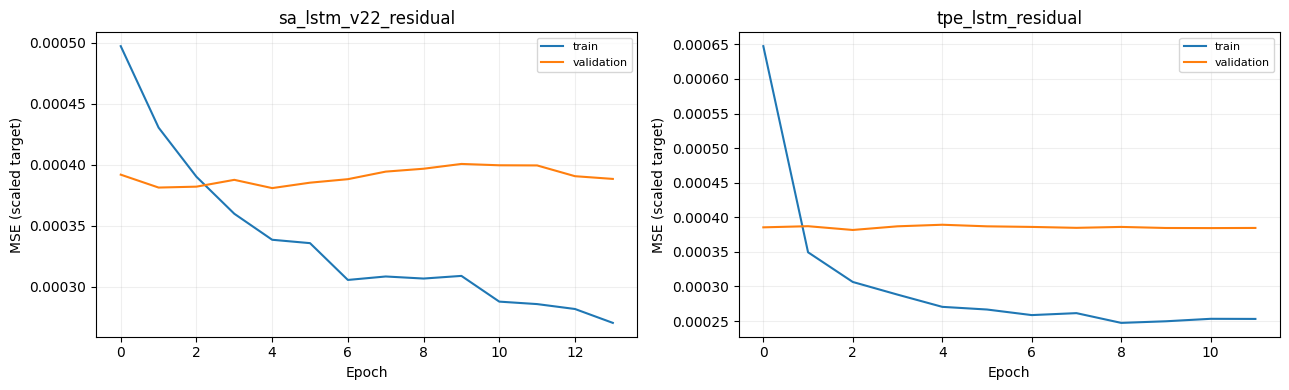

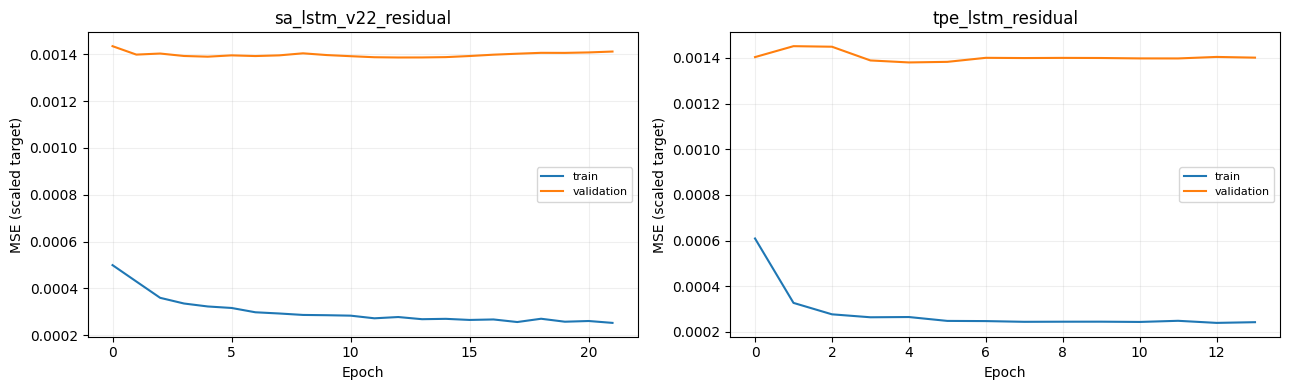

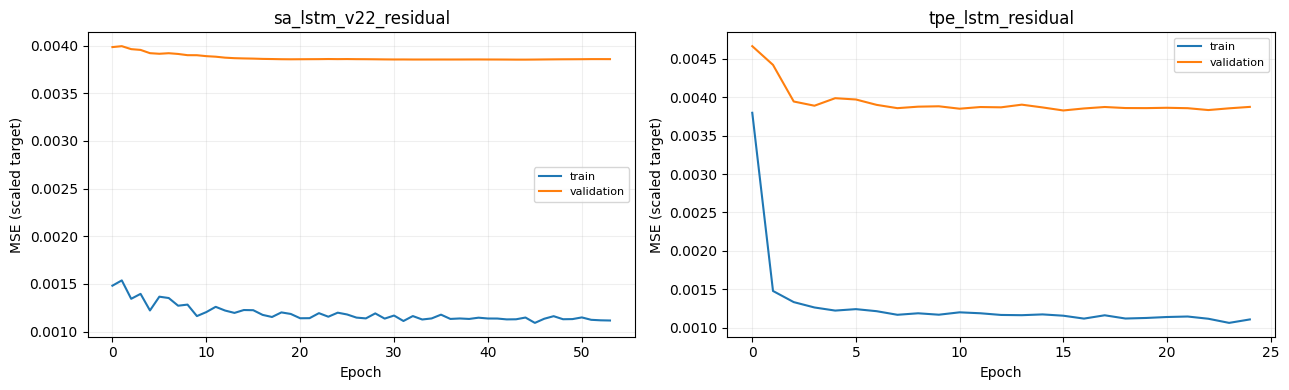

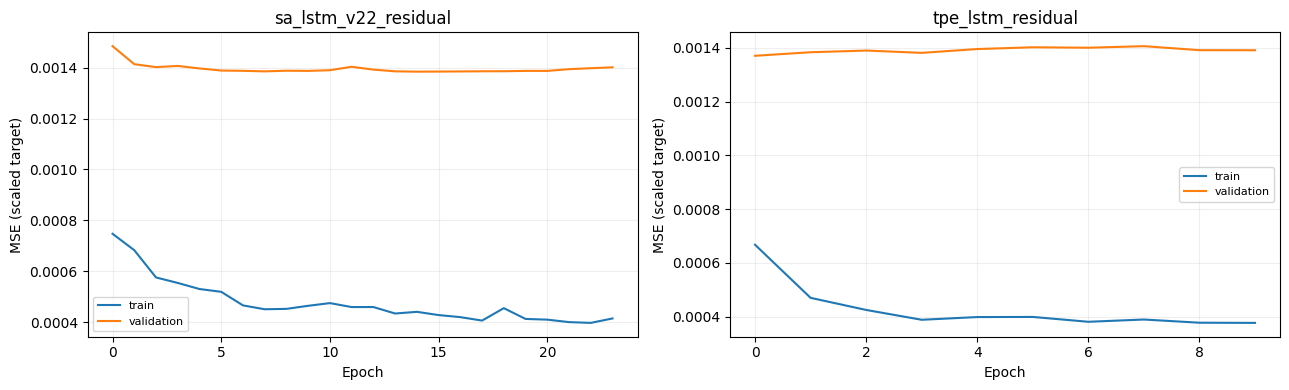

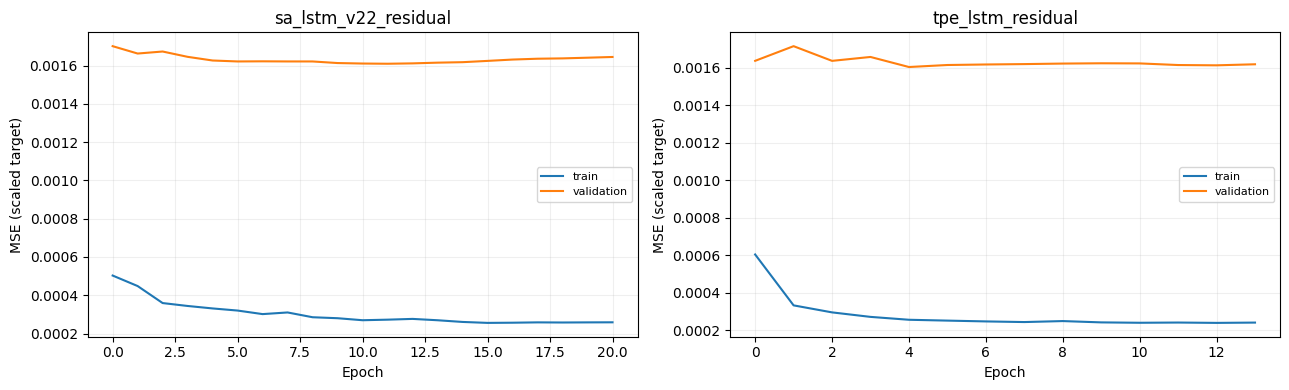

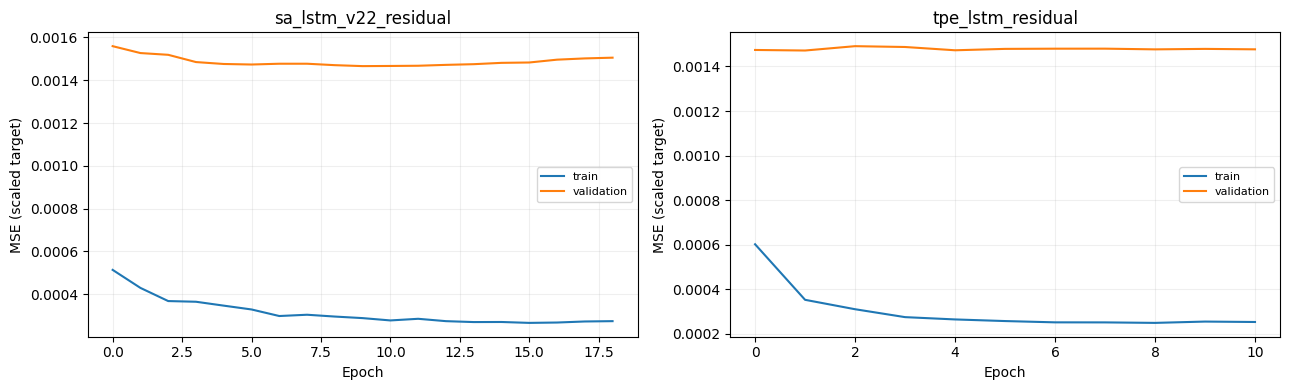

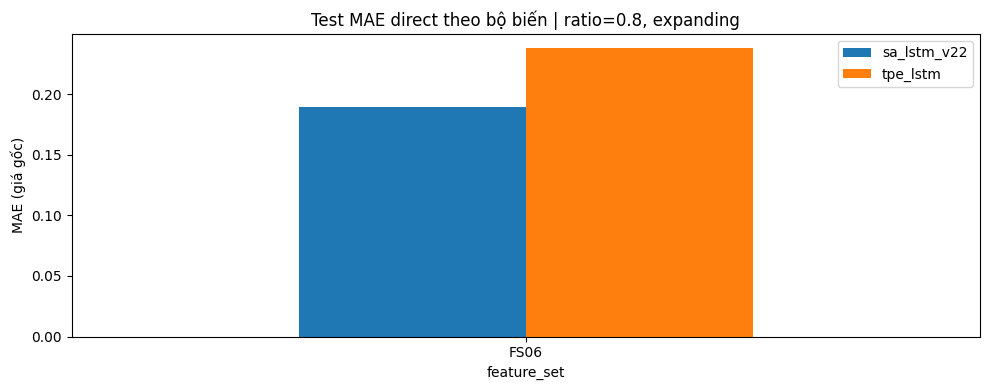

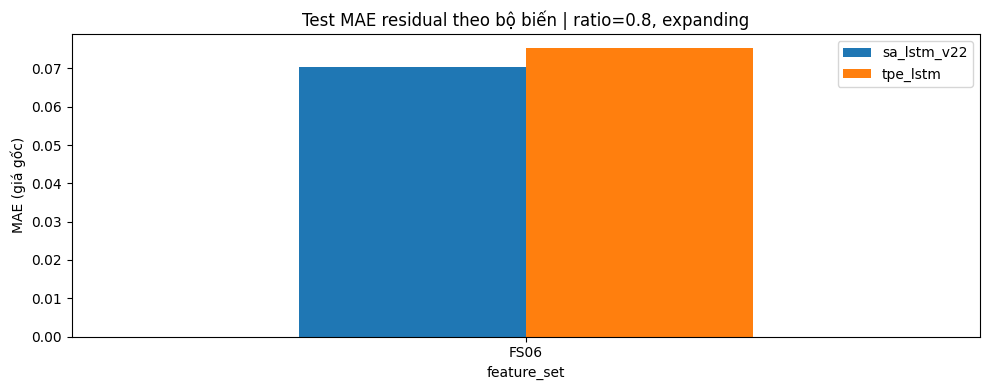

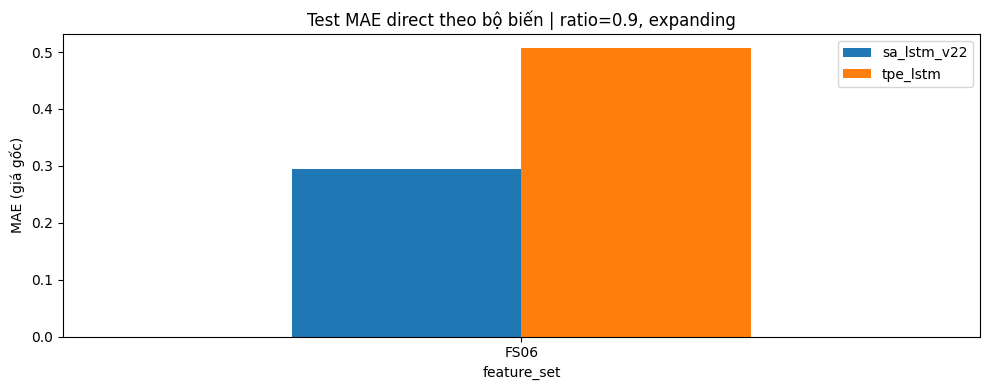

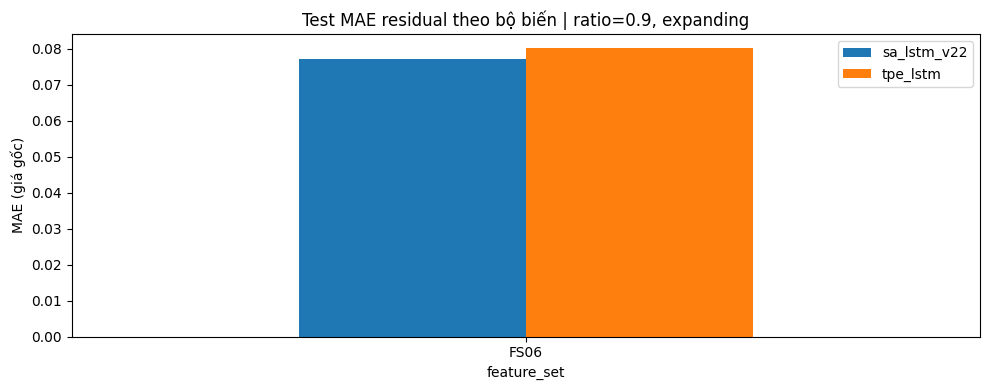

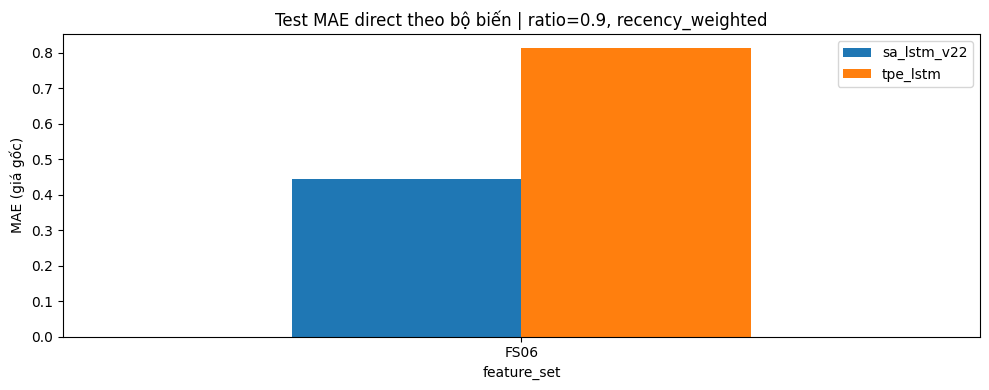

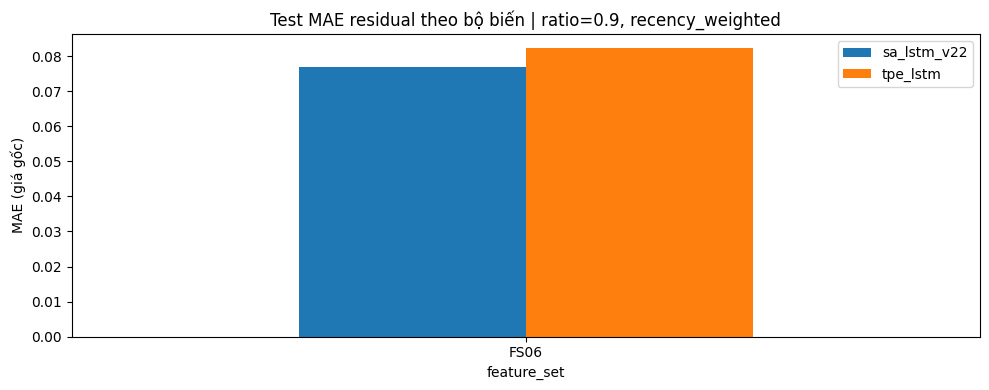

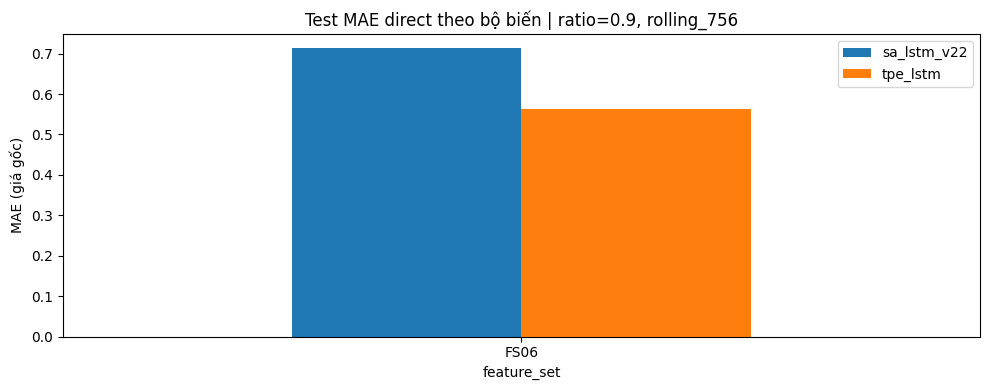

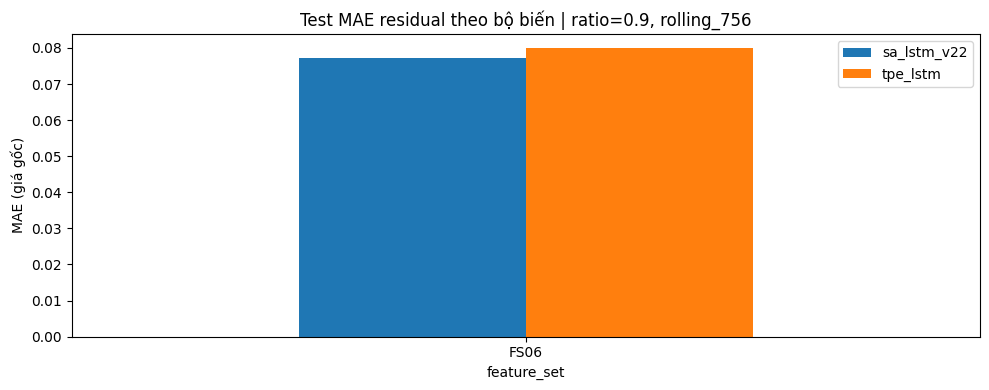

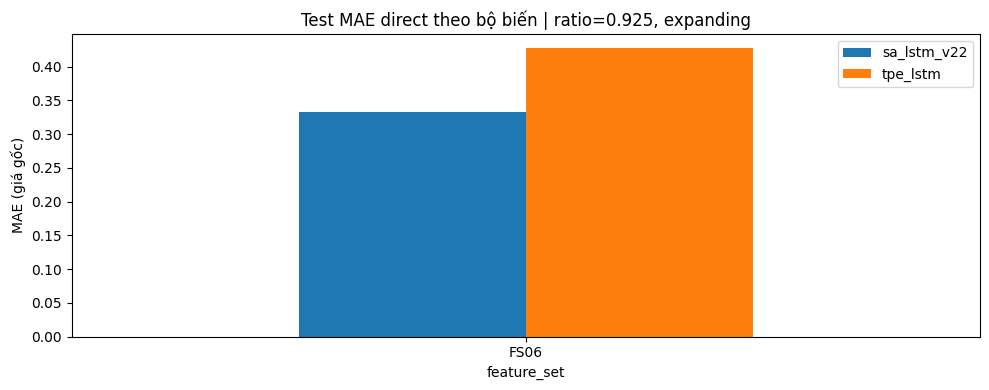

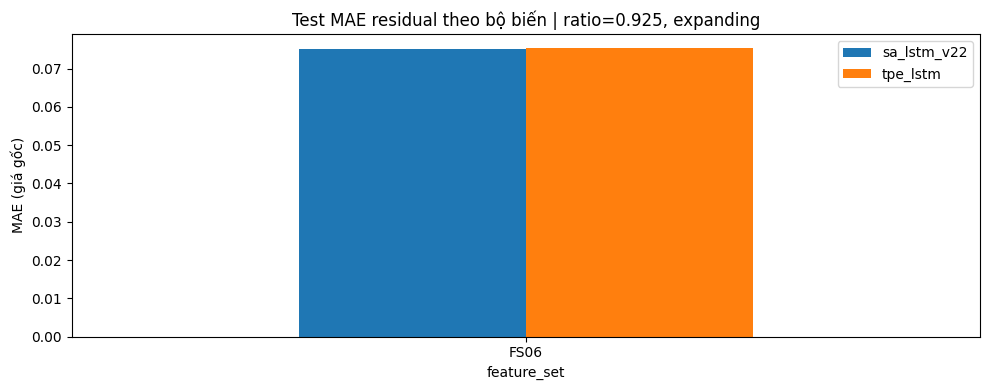

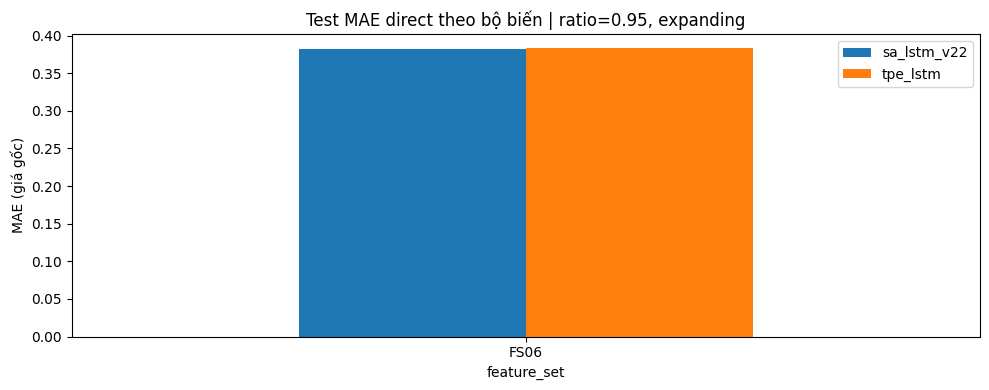

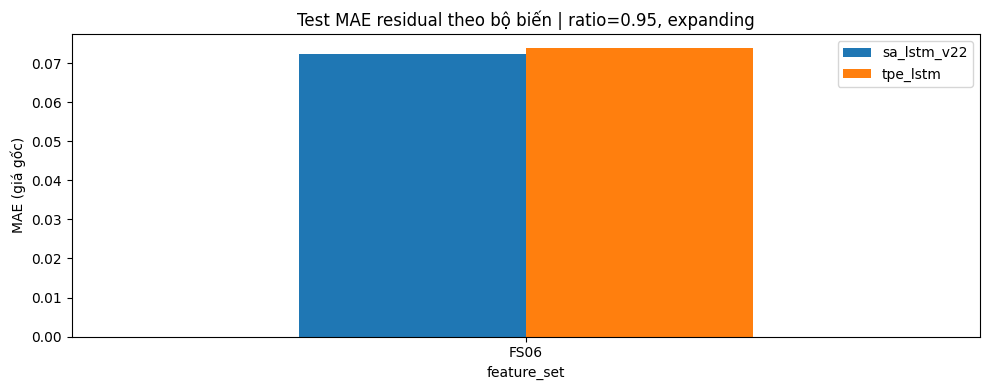

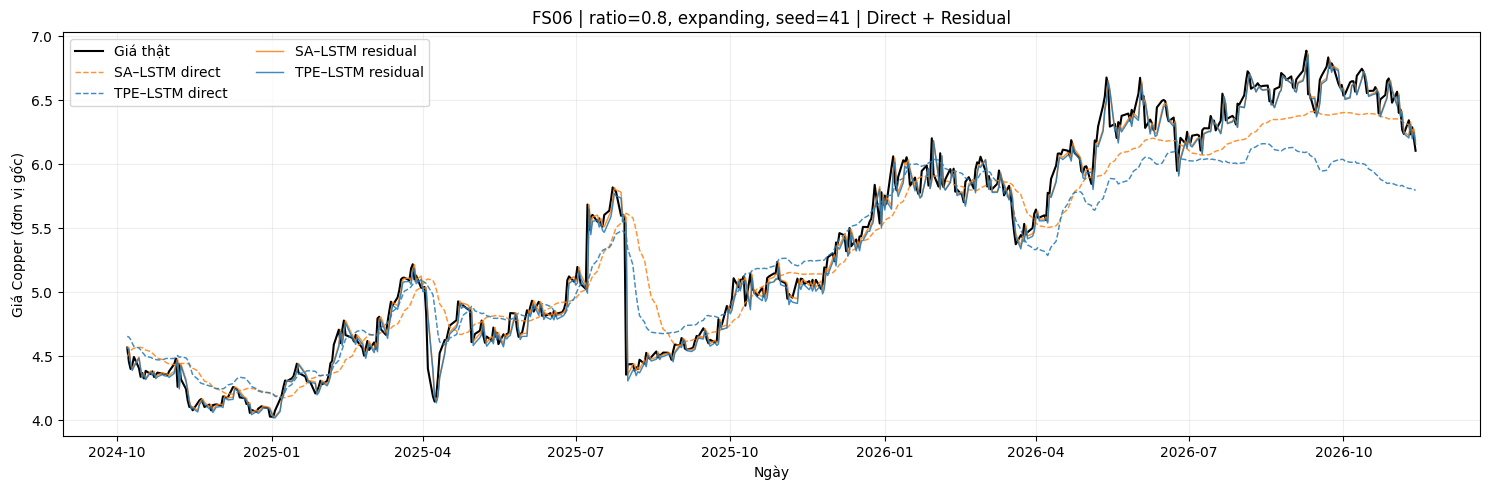

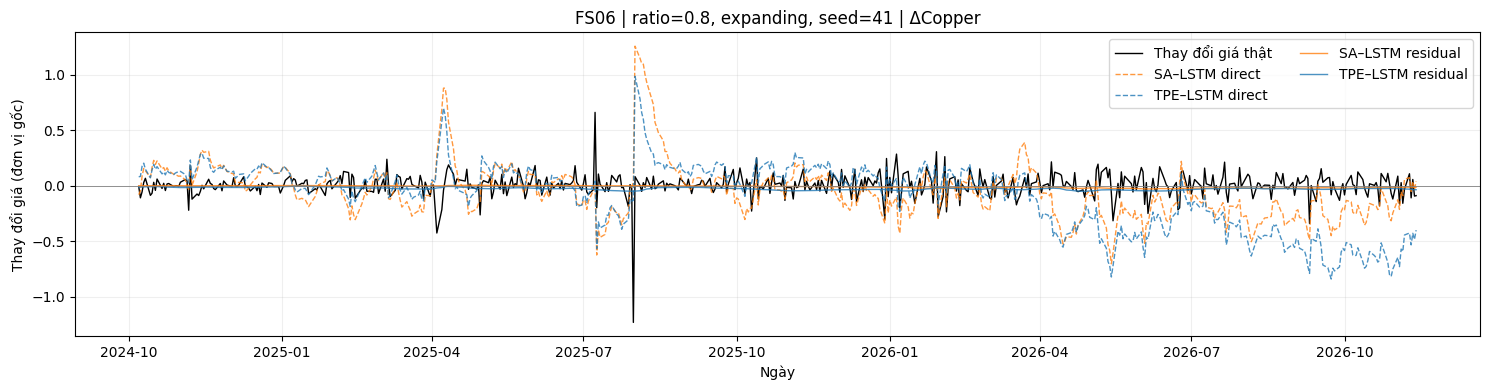

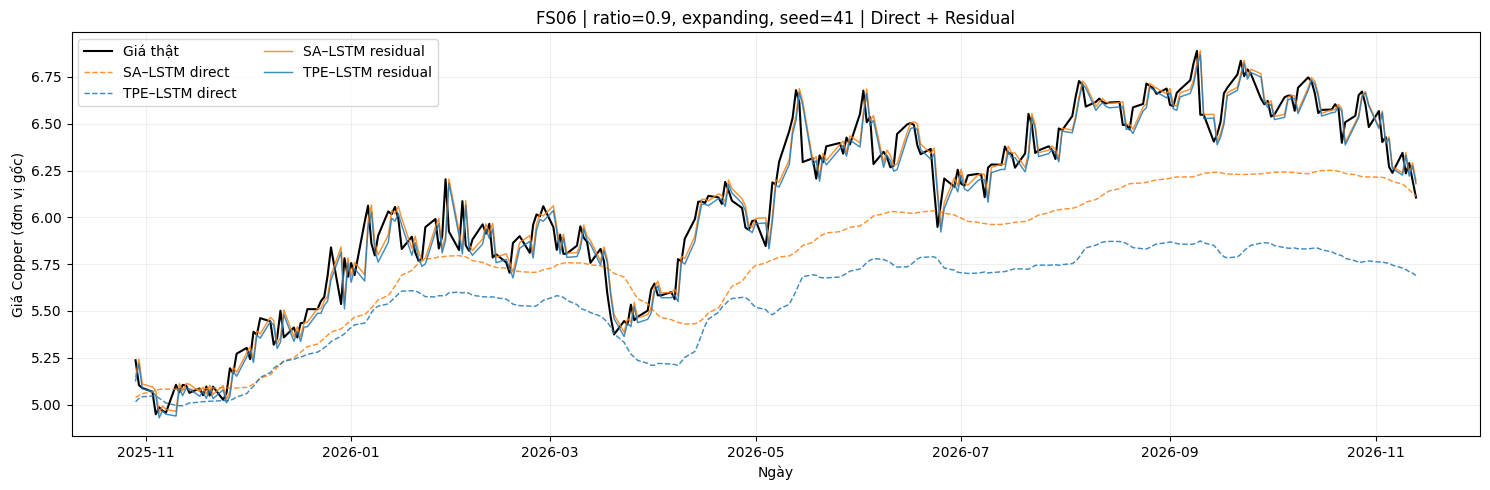

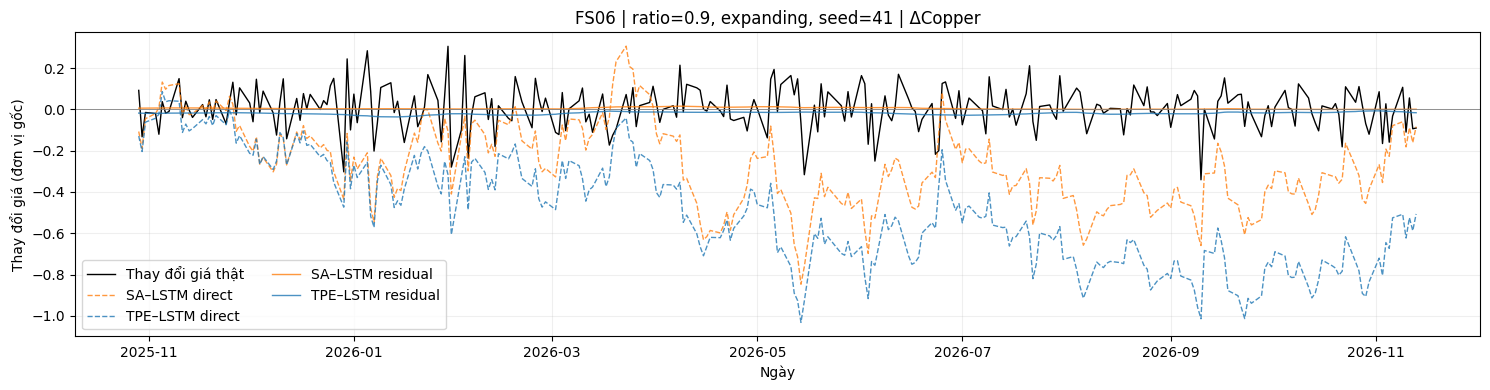

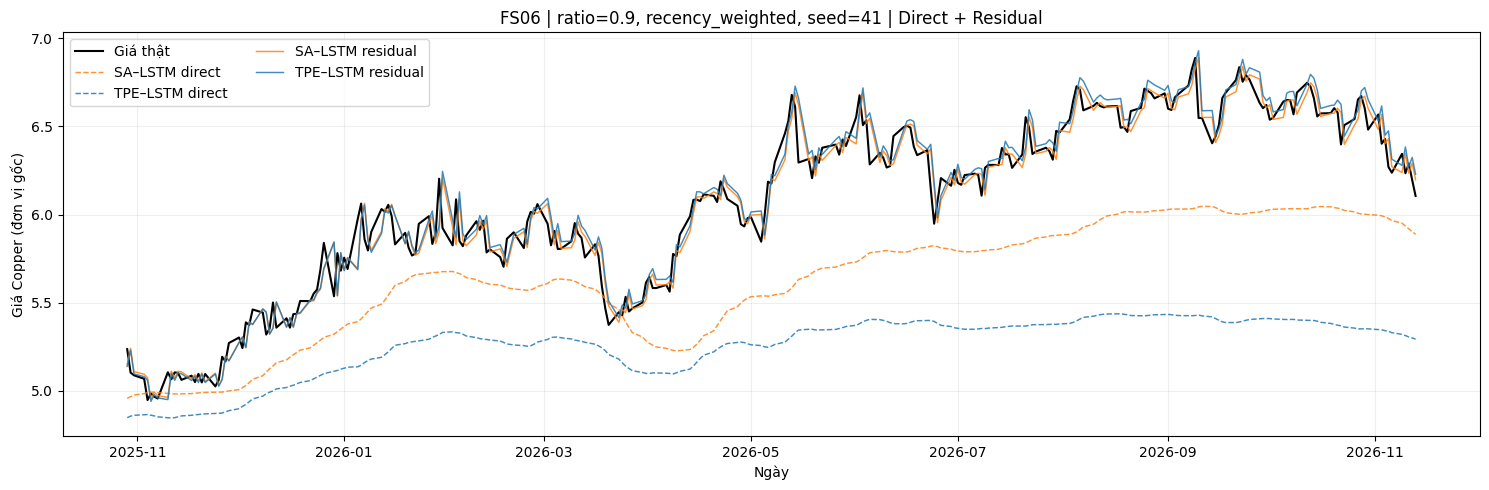

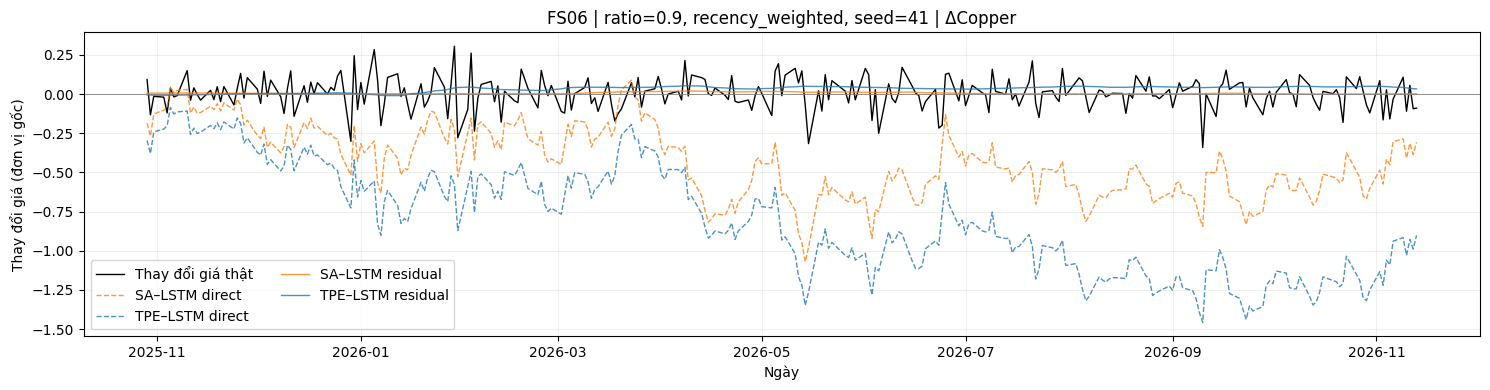

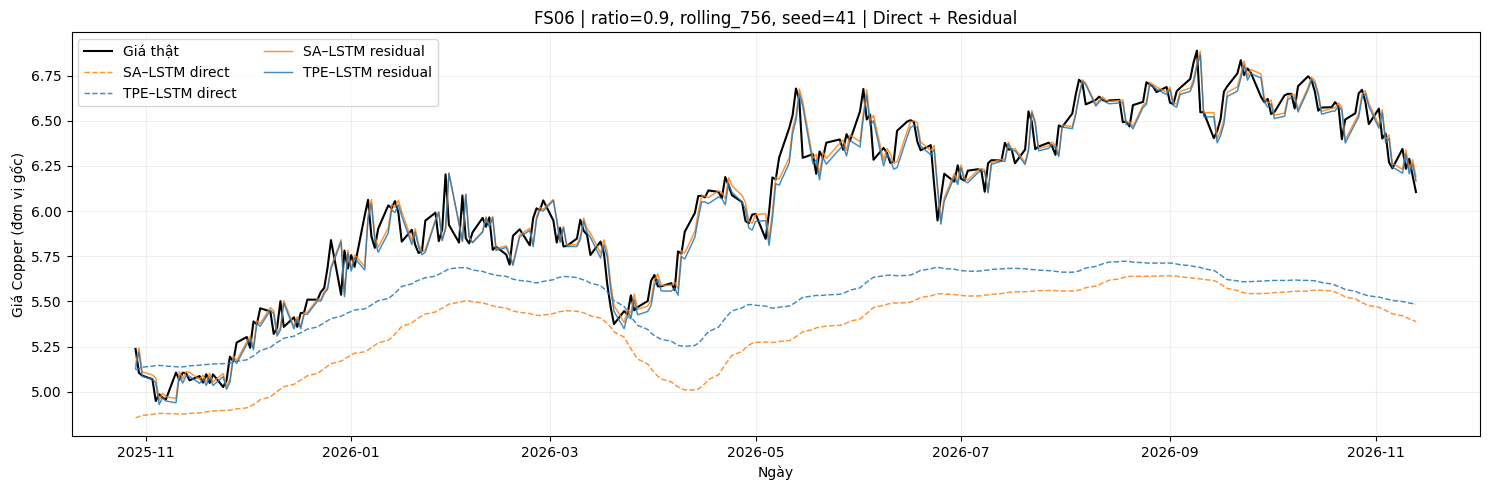

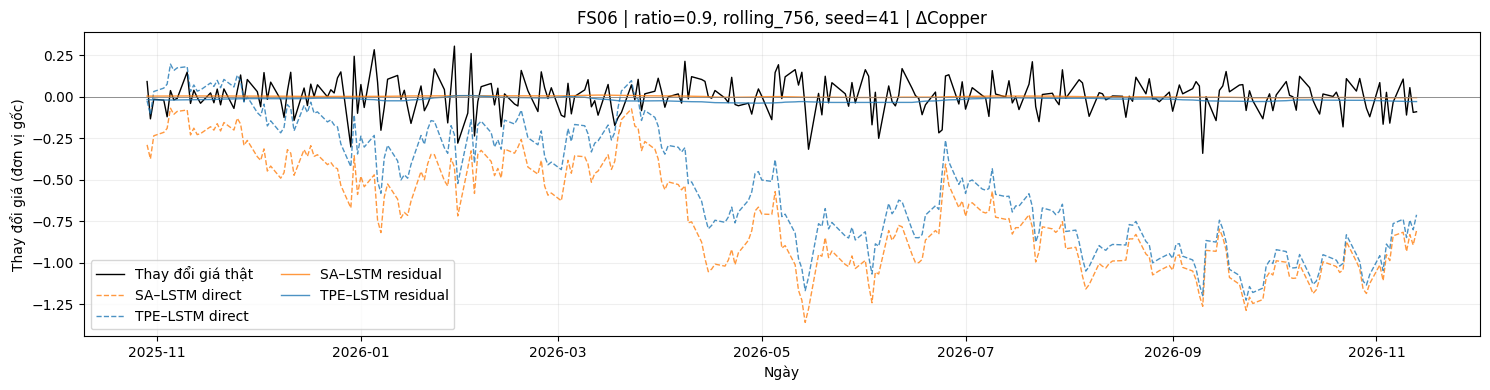

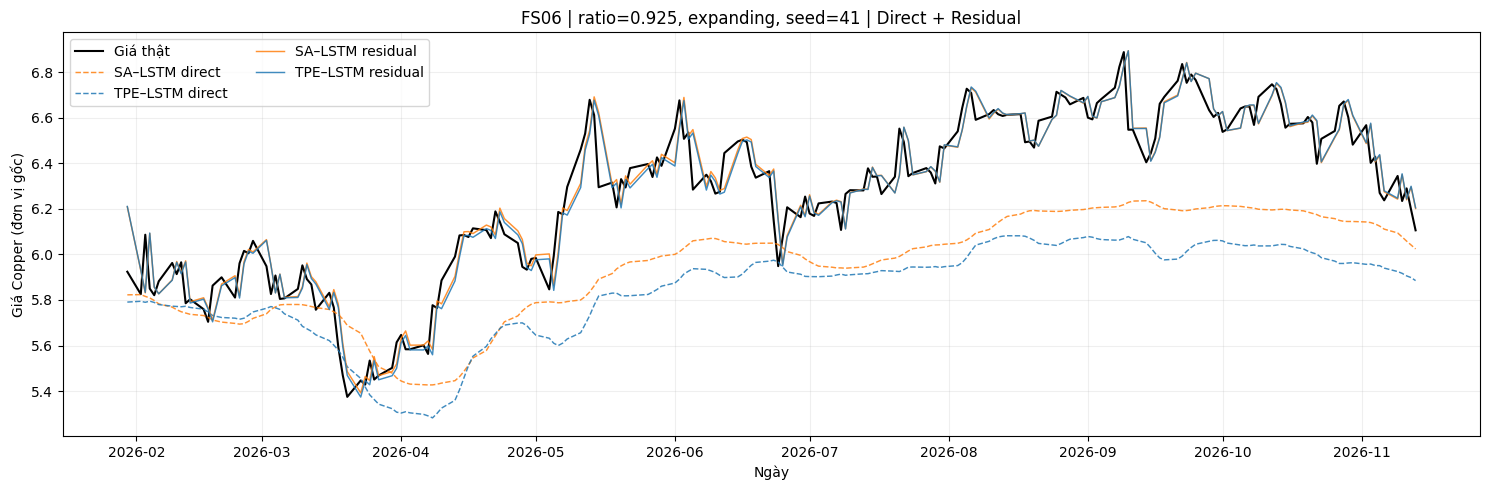

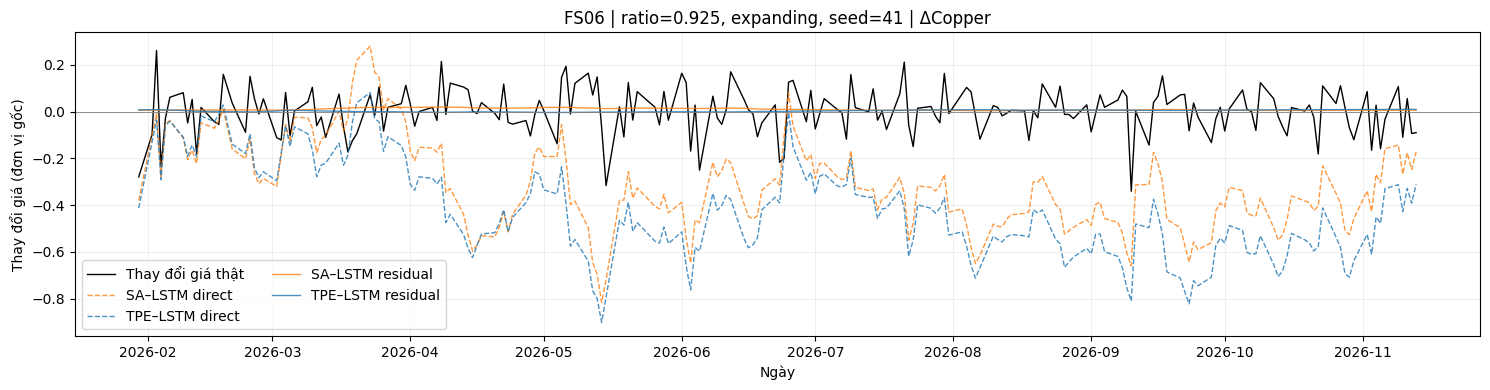

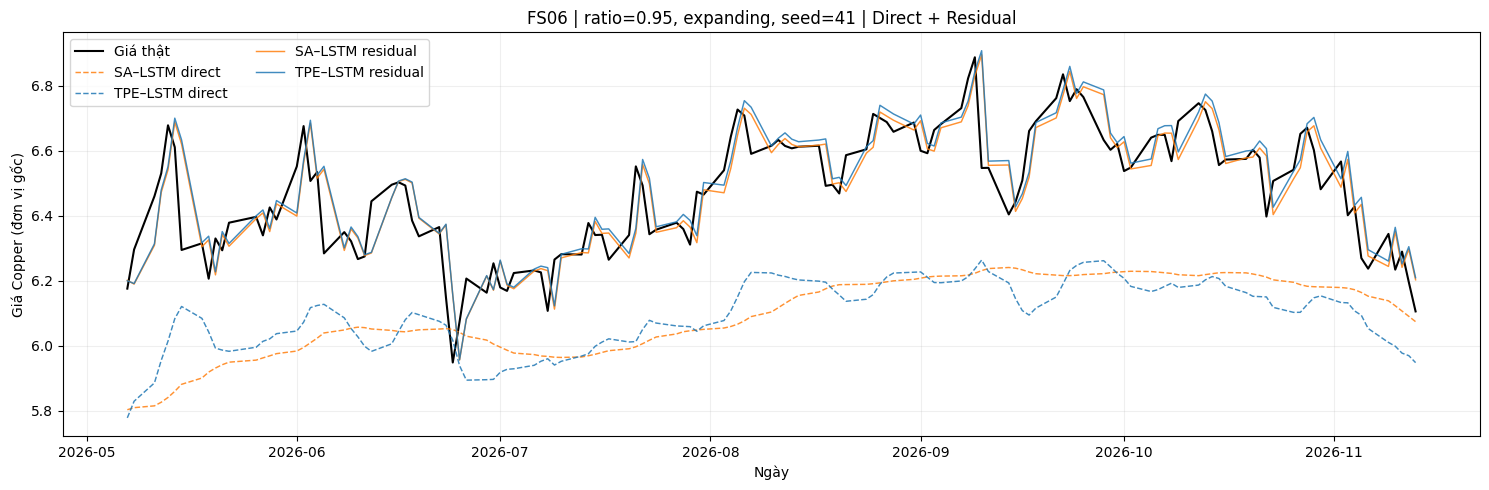

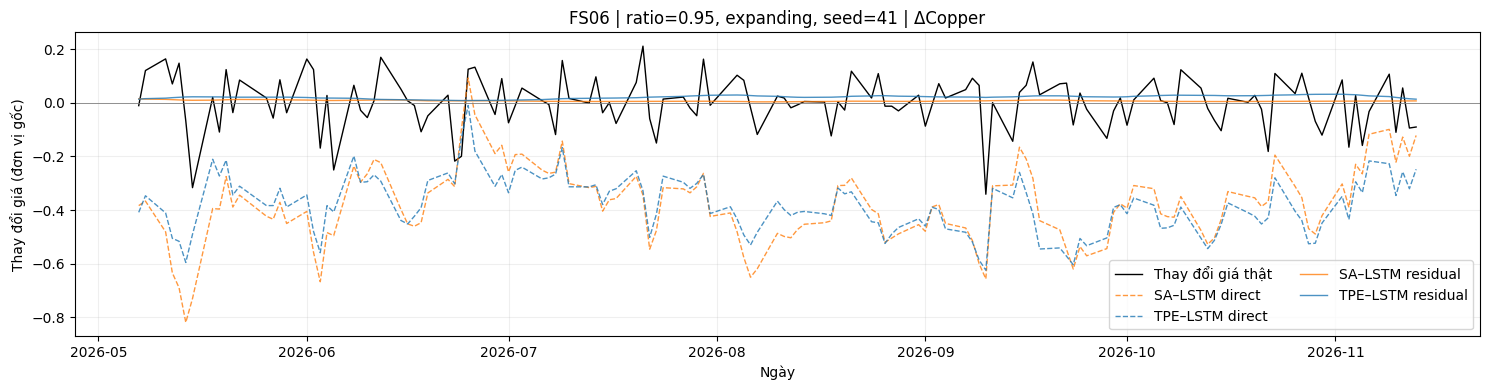

Đã tạo 12 hình ghép tại: /kaggle/working/copper_sa_tpe_FS06_direct_residual_seeds41_45/20261126T135617971746Z/merged_figures


In [16]:
for feature_set in ACTIVE_FEATURE_SETS:
    plot_dir=OUT/feature_set/'figures';plot_dir.mkdir(parents=True,exist_ok=True)
    for forecast_mode in FORECAST_MODES:
        mode_labels=[f'{method}_{forecast_mode}' for method in BASE_METHODS]
        for seed in SEEDS:
            fig,axs=plt.subplots(1,2,figsize=(13,4))
            for (mode,method),g in search_trials[(search_trials.forecast_mode==forecast_mode)&(search_trials.seed==seed)&(search_trials.feature_set==feature_set)].groupby(['forecast_mode','method']):
                g=g.sort_values('trial');label=f'{method} / {mode}'
                axs[0].plot(g.trial,g.best_val_mse_scaled,label=label)
                axs[1].plot(g.elapsed_seconds,g.best_val_mse_scaled,label=label)
            for ax in axs:
                ax.set_ylabel('Best validation MSE (scaled target)');ax.legend(fontsize=7);ax.grid(alpha=.2)
            axs[0].set_xlabel('Model evaluations');axs[1].set_xlabel('Search elapsed seconds')
            fig.suptitle(f'{feature_set} Search 80/20 expanding, seed={seed} ({forecast_mode} target)')
            fig.tight_layout();fig.savefig(plot_dir/f'{forecast_mode}_search_convergence_{seed}.png',dpi=150)
            plt.show();plt.close(fig)

        for ratio,scheme in JOBS:
            fig,axs=plt.subplots(1,2,figsize=(13,4))
            for ax,model_key in zip(axs.ravel(),mode_labels):
                recipe=next(r for r in final_models if r['feature_set']==feature_set and r['model_key']==model_key and
                            r['ratio']==ratio and r['scheme']==scheme and r['seed']==SEEDS[0])
                hist=pd.read_csv(Path(recipe['model_path']).with_name(f'{model_key}_loss.csv'))
                ax.plot(hist.loss,label='train');ax.plot(hist.val_loss,label='validation')
                ax.set(title=model_key,xlabel='Epoch',ylabel='MSE (scaled target)')
                ax.legend(fontsize=8);ax.grid(alpha=.2)
            fig.tight_layout();fig.savefig(plot_dir/f'{forecast_mode}_loss_{ratio}_{scheme}.png',dpi=150)
            plt.show();plt.close(fig)


for (ratio,scheme,forecast_mode),part in results_df[results_df.seed==SEEDS[0]].groupby(['ratio','scheme','forecast_mode']):
    table=part.pivot(index='feature_set',columns='method',values='mae').reindex(ACTIVE_FEATURE_SETS)
    ax=table.plot.bar(figsize=(10,4),rot=0)
    ax.set(title=f'Test MAE {forecast_mode} theo bộ biến | ratio={ratio}, {scheme}',ylabel='MAE (giá gốc)')
    ax.legend();ax.figure.tight_layout()
    ax.figure.savefig(OUT/f'{forecast_mode}_feature_sets_mae_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(ax.figure)


def plot_direct_residual_together(predictions_df, output_dir, plot_seeds):
    required={'feature_set','ratio','scheme','seed','method','forecast_mode','Date','actual','pred'}
    missing=required-set(predictions_df.columns)
    if missing:raise ValueError(f'CSV thiếu cột: {sorted(missing)}')
    df=predictions_df.copy()
    df['Date']=pd.to_datetime(df['Date'],errors='raise')
    df['seed']=pd.to_numeric(df['seed'],errors='raise').astype(int)
    for c in ['actual','pred']:
        df[c]=pd.to_numeric(df[c],errors='raise')
        if not np.isfinite(df[c]).all():raise ValueError(f'{c} có giá trị không hữu hạn')
    missing_seeds=set(plot_seeds)-set(df.seed.unique())
    if missing_seeds:raise ValueError(f'Chưa có kết quả seeds {sorted(missing_seeds)}; sửa PLOT_SEEDS theo CSV.')
    styles={
        ('sa_lstm_v22','direct'):('SA–LSTM direct','tab:orange','--'),
        ('tpe_lstm','direct'):('TPE–LSTM direct','tab:blue','--'),
        ('sa_lstm_v22','residual'):('SA–LSTM residual','tab:orange','-'),
        ('tpe_lstm','residual'):('TPE–LSTM residual','tab:blue','-'),
    }
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    saved=[]
    for (fs,ratio,scheme,seed),part in df[df.seed.isin(plot_seeds)].groupby(['feature_set','ratio','scheme','seed']):
        keys=set(zip(part.method,part.forecast_mode))
        missing_models=set(styles)-keys
        if missing_models:
            raise ValueError(f'{fs}, ratio={ratio}, {scheme}, seed={seed}: thiếu {sorted(missing_models)}. '
                             'Cần CSV đã có kết quả của cả direct và residual; vẽ lại không sinh thêm dự báo.')
        groups={key:part[(part.method==key[0])&(part.forecast_mode==key[1])].sort_values('Date') for key in styles}
        ref=next(iter(groups.values()))
        for key,g in groups.items():
            if g.Date.duplicated().any():raise ValueError(f'Trùng ngày: {fs}, {key}')
            if not np.array_equal(ref.Date.to_numpy(),g.Date.to_numpy()) or not np.allclose(ref.actual,g.actual):
                raise ValueError(f'Các nhánh không cùng ngày/giá thật: {fs}, {key}')
        folder=output_dir/fs;folder.mkdir(parents=True,exist_ok=True)
        tag=f'{ratio:g}_{scheme}_seed{seed}'
        fig,ax=plt.subplots(figsize=(15,5))
        ax.plot(ref.Date,ref.actual,color='black',label='Giá thật',linewidth=1.5)
        for key,(label,color,linestyle) in styles.items():
            g=groups[key]
            ax.plot(g.Date,g.pred,label=label,color=color,linestyle=linestyle,linewidth=1.05,alpha=.85)
        ax.set(title=f'{fs} | ratio={ratio:g}, {scheme}, seed={seed} | Direct + Residual',
               xlabel='Ngày',ylabel='Giá Copper (đơn vị gốc)')
        ax.legend(ncol=2);ax.grid(alpha=.2);fig.tight_layout()
        path=folder/f'merged_price_{tag}.png';fig.savefig(path,dpi=160);saved.append(path)
        plt.show();plt.close(fig)
        # Các thống kê delta đã được tạo khi đánh giá; không chạy lại mô hình.
        if {'actual_delta','pred_delta'} <= set(part.columns):
            fig,ax=plt.subplots(figsize=(15,4))
            ax.plot(ref.Date,ref.actual_delta,color='black',label='Thay đổi giá thật',linewidth=1)
            for key,(label,color,linestyle) in styles.items():
                g=groups[key]
                ax.plot(g.Date,g.pred_delta,label=label,color=color,linestyle=linestyle,linewidth=1,alpha=.8)
            ax.axhline(0,color='gray',linewidth=.6)
            ax.set(title=f'{fs} | ratio={ratio:g}, {scheme}, seed={seed} | ΔCopper',
                   xlabel='Ngày',ylabel='Thay đổi giá (đơn vị gốc)')
            ax.legend(ncol=2);ax.grid(alpha=.2);fig.tight_layout()
            path=folder/f'merged_delta_{tag}.png';fig.savefig(path,dpi=160);saved.append(path)
            plt.show();plt.close(fig)
    return saved

PLOT_SEEDS=[41]  # Đổi thành [41,42,43,44,45] nếu muốn vẽ từng seed.
merged_files=plot_direct_residual_together(predictions_df,OUT/'merged_figures',PLOT_SEEDS)
print(f'Đã tạo {len(merged_files)} hình ghép tại: {OUT / "merged_figures"}')


## 8. Kết quả

- `manifest.json`: định nghĩa đầy đủ các bộ biến đang chạy, dữ liệu, ngân sách và seeds.
- `metrics_by_run.csv`: 120 dòng kết quả của FS06 và seeds 41–45; có cột feature_set.
- `paired_comparison_SA_vs_TPE_by_mode.csv`: 60 cặp SA/TPE cùng bộ/ratio/scheme/seed.
- `paired_comparison_residual_vs_direct.csv`: chênh lệch residual − direct trên cùng bộ/split/sampler/seed.
- `feature_set_comparison_mae.csv`: bảng MAE của FS06 theo ratio/scheme/seed/target.
- `search_comparison.csv`, `all_search_trials.csv`, `locked_best_hyperparameters.json`: search riêng cho từng bộ/target.
- `data_split_summary.csv`, `final_training.csv`, `test_predictions.csv`, `summary_mean_std.csv` và model/scalers/loss/figures theo thư mục FSxx.
- ZIP chứa toàn bộ kết quả. `summary_mean_std.csv` báo mean/std của 5 seeds cho từng bộ/ratio/scheme/target/phương pháp. Kết quả quick chỉ kiểm tra luồng.


In [17]:
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file():z.write(file,arcname=str(file.relative_to(OUT)))
print('Results:',OUT)
print('ZIP:',zip_path)
display(FileLink(str(zip_path)))


Results: /kaggle/working/copper_sa_tpe_FS06_direct_residual_seeds41_45/20261126T135617971746Z
ZIP: /kaggle/working/copper_sa_tpe_FS06_direct_residual_seeds41_45/20261126T135617971746Z_results.zip


/kaggle/working/copper_sa_tpe_FS06_direct_residual_seeds41_45/20261126T135617971746Z_results.zip